# Wavelet-Based Time–Frequency Analysis Pipeline
### Haemograph Microfluidic Rheometer — Full Analysis (Phases A–W)
---

## Phase A — Data Integrity & Experimental Validation

In [1]:
import pandas as pd
import numpy as np

file_path = "egg-yolk-rawdata.xlsx"
xls = pd.ExcelFile(file_path)

clean_data = {}
phase_A_summary = {}

for sheet in xls.sheet_names:
    df_raw = pd.read_excel(file_path, sheet_name=sheet, header=None)
    df = df_raw.dropna(how='all').dropna(axis=1, how='all')
    numeric_df = df.apply(pd.to_numeric, errors='coerce')
    numeric_rows = numeric_df.dropna(thresh=int(0.5 * numeric_df.shape[1]))

    if numeric_rows.shape[0] == 0:
        phase_A_summary[sheet] = {"status": "FAIL_no_numeric_block"}
        continue

    numeric_rows = numeric_rows.reset_index(drop=True)
    time_col = numeric_rows.iloc[:, 0]
    is_monotonic = time_col.is_monotonic_increasing
    diffs = np.diff(time_col.dropna())
    sampling_std = np.std(diffs) if len(diffs) > 0 else None

    clean_data[sheet] = {
        "data": numeric_rows,
        "time": time_col,
        "sampling_std": sampling_std
    }

    if not is_monotonic:
        status = "FAIL_time_not_monotonic"
    elif sampling_std is not None and sampling_std > 0.01:
        status = "WARN_irregular_sampling"
    else:
        status = "PASS"

    phase_A_summary[sheet] = {
        "rows": numeric_rows.shape[0],
        "cols": numeric_rows.shape[1],
        "sampling_std": sampling_std,
        "status": status
    }

usable_data = {}
for sheet, info in phase_A_summary.items():
    if info.get("status") in ["PASS", "WARN_irregular_sampling"]:
        usable_data[sheet] = clean_data[sheet]

print("Phase A Summary:")
for k, v in phase_A_summary.items():
    print(f"  {k}: {v}")
print("\nUsable sheets:", list(usable_data.keys()))

Phase A Summary:
  README: {'status': 'FAIL_no_numeric_block'}
  SAOS - G'(T)G"(T): {'rows': 21, 'cols': 84, 'sampling_std': np.float64(0.0), 'status': 'PASS'}
  SAOS - G'(omega)G"(omega): {'rows': 28, 'cols': 63, 'sampling_std': np.float64(5.781988852410561), 'status': 'FAIL_time_not_monotonic'}
  Steady shear - G(t): {'rows': 250, 'cols': 22, 'sampling_std': np.float64(2.457725523151661), 'status': 'WARN_irregular_sampling'}
  Steady shear - J(t): {'rows': 512, 'cols': 22, 'sampling_std': np.float64(1.0823241562799288), 'status': 'WARN_irregular_sampling'}
  Steady shear - eta(gammaDot): {'rows': 26, 'cols': 44, 'sampling_std': np.float64(6.786665607403459), 'status': 'WARN_irregular_sampling'}
  LAOS - G'(gamma_0) G"(gamma_0): {'rows': 21, 'cols': 6, 'sampling_std': np.float64(93.50508912224291), 'status': 'WARN_irregular_sampling'}

Usable sheets: ['SAOS - G\'(T)G"(T)', 'Steady shear - G(t)', 'Steady shear - J(t)', 'Steady shear - eta(gammaDot)', 'LAOS - G\'(gamma_0) G"(gamma_0)']


## Phase B — Advanced Signal Diagnostics (CORRECTED)

**Corrections applied:**
- Signal selected by max variance column, not blindly first column (avoids time-axis as signal)
- Transient flag now uses absolute percentile of energy_diff, not relative to itself
- Trend threshold made data-scale-aware (relative, not absolute)
- ADF/KPSS conflict explicitly handled (four-way decision table)
- Added mutation onset flag (early-stage structural change detector)

In [2]:
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')

phase_B_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]

    # ── FIX 1: select highest-variance non-time column as signal ──────────────
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    best_col = variances.idxmax()
    signal = data[best_col].dropna().astype(float)

    result = {}

    # ADF test
    try:
        adf_stat, adf_p, *_ = adfuller(signal)
    except Exception:
        adf_p = None

    # KPSS test
    try:
        kpss_stat, kpss_p, *_ = kpss(signal, nlags="auto")
    except Exception:
        kpss_p = None

    # ── FIX 2: four-way stationarity decision ─────────────────────────────────
    if adf_p is not None and kpss_p is not None:
        if adf_p < 0.05 and kpss_p > 0.05:
            stationarity = "stationary"
        elif adf_p >= 0.05 and kpss_p <= 0.05:
            stationarity = "non_stationary"
        elif adf_p < 0.05 and kpss_p <= 0.05:
            stationarity = "difference_stationary"    # unit root present but trend-stationary
        else:
            stationarity = "inconclusive"
    else:
        stationarity = "test_failed"

    # ── FIX 3: relative trend threshold ──────────────────────────────────────
    t = np.arange(len(signal))
    trend_slope = np.polyfit(t, signal, 1)[0]
    signal_range = signal.max() - signal.min()
    relative_trend = abs(trend_slope * len(signal)) / (signal_range + 1e-12)
    drift_flag = "drift_present" if relative_trend > 0.05 else "no_drift"

    # ── FIX 4: transient detection — rolling energy std ───────────────────────
    energy = signal ** 2
    window = max(5, len(signal) // 10)
    rolling_std = energy.rolling(window).std().dropna()
    global_std = rolling_std.mean()
    transient_score = rolling_std.max() / (global_std + 1e-12)
    transient_flag = "strong_transient" if transient_score > 3.0 else "weak_transient"

    # ── FIX 5: mutation onset — first derivative spike detection ──────────────
    d1 = np.gradient(signal.values)
    d1_z = (d1 - np.mean(d1)) / (np.std(d1) + 1e-12)
    onset_idx = np.where(np.abs(d1_z) > 3)[0]
    mutation_onset = int(onset_idx[0]) if len(onset_idx) > 0 else None

    phase_B_results[sheet] = {
        "signal_column": best_col,
        "adf_p": adf_p,
        "kpss_p": kpss_p,
        "stationarity": stationarity,
        "relative_trend": relative_trend,
        "drift": drift_flag,
        "transient_score": transient_score,
        "transient": transient_flag,
        "mutation_onset_index": mutation_onset
    }

print("Phase B Results (Corrected):")
for k, v in phase_B_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        print(f"    {kk}: {vv}")

Phase B Results (Corrected):

  [SAOS - G'(T)G"(T)]
    signal_column: 109
    adf_p: 1.0
    kpss_p: 0.01966829841252258
    stationarity: non_stationary
    relative_trend: 0.9679273850149737
    drift: drift_present
    transient_score: 4.681880629054607
    transient: strong_transient
    mutation_onset_index: None

  [Steady shear - G(t)]
    signal_column: 20
    adf_p: 1.0
    kpss_p: 0.09996488458594496
    stationarity: inconclusive
    relative_trend: 0.027347967953345587
    drift: no_drift
    transient_score: 113.45673123433733
    transient: strong_transient
    mutation_onset_index: 0

  [Steady shear - J(t)]
    signal_column: 3
    adf_p: 1.0
    kpss_p: 0.01
    stationarity: non_stationary
    relative_trend: 0.5350795703192979
    drift: drift_present
    transient_score: 15.869010916774394
    transient: strong_transient
    mutation_onset_index: 482

  [Steady shear - eta(gammaDot)]
    signal_column: 40
    adf_p: 0.14940570493618793
    kpss_p: 0.039301130761410

## Phase C — Signal Energy & Information Content

In [3]:
from scipy.fft import rfft, rfftfreq
from scipy.signal import spectrogram
import matplotlib.pyplot as plt

phase_C_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)
    dt = 1.0  # normalised

    # Total signal energy
    total_energy = np.sum(signal ** 2)

    # FFT energy distribution
    S = rfft(signal)
    freqs = rfftfreq(N, d=dt)
    power = np.abs(S) ** 2
    power_norm = power / (power.sum() + 1e-12)

    # Shannon entropy of power spectrum
    shannon_entropy = -np.sum(power_norm * np.log2(power_norm + 1e-12))

    # Spectral entropy (normalised)
    spectral_entropy = shannon_entropy / np.log2(len(power_norm) + 1)

    # Time-localised energy map via short spectrogram
    nperseg = min(64, N // 4)
    f_sg, t_sg, Sxx = spectrogram(signal, fs=1.0, nperseg=nperseg)
    time_energy_map = Sxx.sum(axis=0)   # energy per time window

    # Frequency band energy (low / mid / high thirds)
    third = len(freqs) // 3
    e_low  = power[:third].sum()  / total_energy
    e_mid  = power[third:2*third].sum() / total_energy
    e_high = power[2*third:].sum() / total_energy

    phase_C_results[sheet] = {
        "total_energy": total_energy,
        "shannon_entropy": shannon_entropy,
        "spectral_entropy_norm": spectral_entropy,
        "energy_low_band_frac": e_low,
        "energy_mid_band_frac": e_mid,
        "energy_high_band_frac": e_high,
        "time_energy_map": time_energy_map
    }

print("Phase C — Energy & Information Content:")
for k, v in phase_C_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        if kk != 'time_energy_map':
            print(f"    {kk}: {vv:.4f}" if isinstance(vv, float) else f"    {kk}: {vv}")

Phase C — Energy & Information Content:

  [SAOS - G'(T)G"(T)]
    total_energy: 1770088521.3061
    shannon_entropy: 1.9569
    spectral_entropy_norm: 0.5459
    energy_low_band_frac: 11.9763
    energy_mid_band_frac: 0.9747
    energy_high_band_frac: 0.5043

  [Steady shear - G(t)]
    total_energy: 447276979805789.6875
    shannon_entropy: 6.8182
    spectral_entropy_norm: 0.9756
    energy_low_band_frac: 59.0246
    energy_mid_band_frac: 48.2566
    energy_high_band_frac: 18.4082

  [Steady shear - J(t)]
    total_energy: 14525856.8898
    shannon_entropy: 3.0544
    spectral_entropy_norm: 0.3813
    energy_low_band_frac: 311.2205
    energy_mid_band_frac: 1.5989
    energy_high_band_frac: 0.8098

  [Steady shear - eta(gammaDot)]
    total_energy: 880132334373.4481
    shannon_entropy: 2.8226
    spectral_entropy_norm: 0.7225
    energy_low_band_frac: 12.4354
    energy_mid_band_frac: 2.0226
    energy_high_band_frac: 1.2109

  [LAOS - G'(gamma_0) G"(gamma_0)]
    total_energy: 330

## Phase D — Noise & Distortion Modeling

In [4]:
from scipy.signal import welch

phase_D_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    # Welch PSD for noise floor
    f_w, psd = welch(signal, fs=1.0, nperseg=min(64, N//2))

    # Noise floor: median of PSD tail (top 20% frequencies)
    noise_floor = np.median(psd[int(0.8 * len(psd)):])

    # SNR: peak power vs noise floor
    peak_power = psd.max()
    snr_db = 10 * np.log10(peak_power / (noise_floor + 1e-12))

    # Frequency-dependent SNR
    snr_freq = 10 * np.log10(psd / (noise_floor + 1e-12))

    # Colored noise estimation: fit log(PSD) ~ beta * log(f)
    valid = f_w > 0
    if valid.sum() > 2:
        beta = np.polyfit(np.log(f_w[valid] + 1e-12), np.log(psd[valid] + 1e-12), 1)[0]
        if beta < -0.5:
            noise_type = f"colored_1/f^{abs(beta):.1f}"
        else:
            noise_type = "white_noise"
    else:
        beta, noise_type = None, "undetermined"

    # Signal distortion index: THD proxy
    S = np.abs(rfft(signal))
    fundamental_idx = np.argmax(S[1:]) + 1
    harmonic_idxs = [fundamental_idx * h for h in [2, 3, 4] if fundamental_idx * h < len(S)]
    harmonic_power = sum(S[i]**2 for i in harmonic_idxs)
    distortion_index = np.sqrt(harmonic_power) / (S[fundamental_idx] + 1e-12)

    # Windowing bias: rectangular vs Hann amplitude ratio
    hann = np.hanning(N)
    S_rect = np.abs(rfft(signal))
    S_hann = np.abs(rfft(signal * hann)) / (hann.mean() + 1e-12)
    window_bias = np.mean(np.abs(S_rect[:fundamental_idx+1] - S_hann[:fundamental_idx+1]) /
                          (S_rect[:fundamental_idx+1] + 1e-12))

    phase_D_results[sheet] = {
        "noise_floor": noise_floor,
        "snr_db": snr_db,
        "noise_beta": beta,
        "noise_type": noise_type,
        "distortion_index": distortion_index,
        "window_amplitude_bias": window_bias,
        "psd": psd,
        "snr_freq": snr_freq
    }

print("Phase D — Noise & Distortion:")
for k, v in phase_D_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        if kk not in ['psd', 'snr_freq']:
            print(f"    {kk}: {vv}")

Phase D — Noise & Distortion:

  [SAOS - G'(T)G"(T)]
    noise_floor: 8528.385247349746
    snr_db: 38.588560473158545
    noise_beta: -7.36545010581528
    noise_type: colored_1/f^7.4
    distortion_index: 0.6861372028396372
    window_amplitude_bias: 0.4981514884242405

  [Steady shear - G(t)]
    noise_floor: 68913061.9735141
    snr_db: 41.89742691111312
    noise_beta: -0.3547158839110038
    noise_type: white_noise
    distortion_index: 1.2164180767396624
    window_amplitude_bias: 0.9949058207952491

  [Steady shear - J(t)]
    noise_floor: 0.0003030163756207759
    snr_db: 79.6671945495821
    noise_beta: -5.711004958790547
    noise_type: colored_1/f^5.7
    distortion_index: 0.9715235146556281
    window_amplitude_bias: 0.6891431986049117

  [Steady shear - eta(gammaDot)]
    noise_floor: 68085.49811827995
    snr_db: 38.1524574291048
    noise_beta: -5.471850494284747
    noise_type: colored_1/f^5.5
    distortion_index: 1.0407015476730619
    window_amplitude_bias: 0.774005

## Phase E — Spectral Leakage & Window Analysis

In [5]:
from scipy.signal.windows import tukey, hann, boxcar

phase_E_results = {}

WINDOWS = {
    "rectangular": lambda N: boxcar(N),
    "hanning":     lambda N: hann(N),
    "tukey_0.25":  lambda N: tukey(N, alpha=0.25),
    "tukey_0.5":   lambda N: tukey(N, alpha=0.5),
}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    # Ground-truth amplitude (no window)
    S_rect = np.abs(rfft(signal))
    fund_idx = np.argmax(S_rect[1:]) + 1
    true_amp = S_rect[fund_idx]

    window_results = {}
    for wname, wfunc in WINDOWS.items():
        w = wfunc(N)
        coherent_gain = w.mean()
        S_w = np.abs(rfft(signal * w)) / coherent_gain

        # Amplitude bias at fundamental
        amp_bias = abs(S_w[fund_idx] - true_amp) / (true_amp + 1e-12)

        # Leakage: energy outside ±2 bins of fundamental, normalised
        mask = np.ones(len(S_w), dtype=bool)
        for b in range(max(0, fund_idx-2), min(len(S_w), fund_idx+3)):
            mask[b] = False
        leakage = (S_w[mask]**2).sum() / ((S_w**2).sum() + 1e-12)

        # Main lobe width (bins at -3 dB)
        peak = S_w[fund_idx]
        half_power = peak / np.sqrt(2)
        lobe_width = np.sum(S_w >= half_power)

        window_results[wname] = {
            "amplitude_bias": amp_bias,
            "leakage_fraction": leakage,
            "main_lobe_width_bins": int(lobe_width)
        }

    # Optimal window: minimise leakage
    best_window = min(window_results, key=lambda w: window_results[w]["leakage_fraction"])

    phase_E_results[sheet] = {
        "windows": window_results,
        "optimal_window": best_window
    }

print("Phase E — Spectral Leakage & Window Analysis:")
for k, v in phase_E_results.items():
    print(f"\n  [{k}] → optimal window: {v['optimal_window']}")
    for wn, wr in v['windows'].items():
        print(f"    {wn}: bias={wr['amplitude_bias']:.4f}, leakage={wr['leakage_fraction']:.4f}, lobe={wr['main_lobe_width_bins']} bins")

Phase E — Spectral Leakage & Window Analysis:

  [SAOS - G'(T)G"(T)] → optimal window: hanning
    rectangular: bias=0.0000, leakage=0.0712, lobe=2 bins
    hanning: bias=0.4878, leakage=0.0014, lobe=2 bins
    tukey_0.25: bias=0.1709, leakage=0.0379, lobe=2 bins
    tukey_0.5: bias=0.3040, leakage=0.0079, lobe=2 bins

  [Steady shear - G(t)] → optimal window: rectangular
    rectangular: bias=0.0000, leakage=0.9429, lobe=87 bins
    hanning: bias=0.9998, leakage=1.0000, lobe=113 bins
    tukey_0.25: bias=0.9982, leakage=0.9984, lobe=113 bins
    tukey_0.5: bias=0.9995, leakage=0.9999, lobe=114 bins

  [Steady shear - J(t)] → optimal window: hanning
    rectangular: bias=0.0000, leakage=0.1985, lobe=3 bins
    hanning: bias=0.7120, leakage=0.0036, lobe=2 bins
    tukey_0.25: bias=0.3380, leakage=0.0627, lobe=2 bins
    tukey_0.5: bias=0.5353, leakage=0.0133, lobe=2 bins

  [Steady shear - eta(gammaDot)] → optimal window: hanning
    rectangular: bias=0.0000, leakage=0.2064, lobe=3 bins

## Phase F — Fourier Ecosystem

In [6]:
from scipy.signal import stft
from scipy.signal.windows import dpss

phase_F_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)
    freqs_fft = rfftfreq(N, d=1.0)

    res = {}

    # 1. Standard FFT
    S_fft = rfft(signal)
    res["FFT"] = {"magnitudes": np.abs(S_fft), "freqs": freqs_fft}

    # 2. Windowed FFT (Hann)
    w = np.hanning(N)
    S_wfft = rfft(signal * w) / w.mean()
    res["Windowed_FFT"] = {"magnitudes": np.abs(S_wfft), "freqs": freqs_fft}

    # 3. STFT (Gabor-style)
    nperseg = min(32, N // 4)
    f_s, t_s, Zxx = stft(signal, fs=1.0, nperseg=nperseg, noverlap=nperseg//2)
    res["STFT"] = {"f": f_s, "t": t_s, "magnitude": np.abs(Zxx)}

    # 4. Multi-taper spectral estimation (Thomson, 3 tapers)
    NW = 4; K = 7
    tapers, _ = dpss(N, NW, Kmax=K, return_ratios=True)
    mt_spectra = np.array([np.abs(rfft(signal * t))**2 for t in tapers])
    mt_psd = mt_spectra.mean(axis=0)
    res["MultiTaper"] = {"psd": mt_psd, "freqs": freqs_fft}

    # 5. Chirp-Z transform (finer frequency resolution around fundamental)
    S_fft_full = np.abs(S_fft)
    fund_idx = np.argmax(S_fft_full[1:]) + 1
    f_start = max(0, freqs_fft[fund_idx] - 0.05)
    f_end   = min(0.5, freqs_fft[fund_idx] + 0.05)
    M_czt = 512
    k = np.arange(M_czt)
    f_czt = f_start + k * (f_end - f_start) / M_czt
    n = np.arange(N)
    czt_result = np.array([
        np.sum(signal * np.exp(-2j * np.pi * f * n))
        for f in f_czt
    ])
    res["ChirpZ"] = {"magnitudes": np.abs(czt_result), "freqs": f_czt}

    # Leakage comparison across methods
    leakage_comparison = {}
    for method in ["FFT", "Windowed_FFT"]:
        mag = res[method]["magnitudes"]
        fi = np.argmax(mag[1:]) + 1
        mask = np.ones(len(mag), dtype=bool)
        for b in range(max(0, fi-2), min(len(mag), fi+3)):
            mask[b] = False
        leakage_comparison[method] = (mag[mask]**2).sum() / ((mag**2).sum() + 1e-12)

    res["leakage_comparison"] = leakage_comparison
    phase_F_results[sheet] = res

print("Phase F — Fourier Ecosystem:")
for k, v in phase_F_results.items():
    print(f"\n  [{k}]")
    print(f"    Methods computed: {[m for m in v.keys() if m != 'leakage_comparison']}")
    print(f"    Leakage — FFT: {v['leakage_comparison']['FFT']:.4f}, "
          f"Windowed: {v['leakage_comparison']['Windowed_FFT']:.4f}")

Phase F — Fourier Ecosystem:

  [SAOS - G'(T)G"(T)]
    Methods computed: ['FFT', 'Windowed_FFT', 'STFT', 'MultiTaper', 'ChirpZ']
    Leakage — FFT: 0.0712, Windowed: 0.0014

  [Steady shear - G(t)]
    Methods computed: ['FFT', 'Windowed_FFT', 'STFT', 'MultiTaper', 'ChirpZ']
    Leakage — FFT: 0.9429, Windowed: 0.0009

  [Steady shear - J(t)]
    Methods computed: ['FFT', 'Windowed_FFT', 'STFT', 'MultiTaper', 'ChirpZ']
    Leakage — FFT: 0.1985, Windowed: 0.0036

  [Steady shear - eta(gammaDot)]
    Methods computed: ['FFT', 'Windowed_FFT', 'STFT', 'MultiTaper', 'ChirpZ']
    Leakage — FFT: 0.2064, Windowed: 0.0069

  [LAOS - G'(gamma_0) G"(gamma_0)]
    Methods computed: ['FFT', 'Windowed_FFT', 'STFT', 'MultiTaper', 'ChirpZ']
    Leakage — FFT: 0.0203, Windowed: 0.0003


## Phase G — Time-Frequency Decomposition (5 Wavelet Algorithms + Data-Driven Selection)

In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# Phase G — 5 wavelet algorithms benchmarked and ranked per sheet.
# Algorithms:
#   1. CWT-Morlet   — continuous, good frequency resolution, scale-adaptive
#   2. CWT-MexHat   — continuous, good for transient/edge detection
#   3. DWT-db4      — discrete, fast, good energy decomposition
#   4. DWT-sym5     — discrete, near-symmetric, better phase response
#   5. Gabor (STFT-Gaussian) — analytical time-frequency, direct uncertainty-optimal
#   6. SST (Synchrosqueezed CWT-cmor) — sharpened TF rep, best for chirp/IF estimation
#
# Selection criteria (all derived from the signal data):
#   - time_freq_concentration : energy concentration in TF plane (higher = better)
#   - reconstruction_error    : ||x - x_reconstructed|| / ||x|| (lower = better)
#   - transient_sensitivity   : std of ridge IF relative to Hilbert IF (lower = better)
#   - computation_time_ms     : wall-clock time (lower = better for real-time)
#
# Best wavelet selected per sheet → stored in phase_G_best_wavelet[sheet]
# ══════════════════════════════════════════════════════════════════════════════

import pywt
import time as time_module
from scipy.signal import hilbert

phase_G_results = {}
phase_G_best_wavelet = {}   # <-- used by Phase R
phase_G_wavelet_scores = {} # <-- used by Phase R

def _cwt_concentration(coeffs):
    """TF energy concentration: 1 - entropy of normalised |W|^2."""
    power = np.abs(coeffs)**2
    p = power / (power.sum() + 1e-12)
    entropy = -np.sum(p * np.log2(p + 1e-12))
    max_entropy = np.log2(p.size)
    return float(1.0 - entropy / (max_entropy + 1e-12))

def _dwt_recon_error(signal, wavelet, level):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    recon  = pywt.waverec(coeffs, wavelet)[:len(signal)]
    return float(np.sqrt(np.mean((signal - recon)**2)) / (np.std(signal) + 1e-12))

def _ridge_if_error(coeffs, freqs, hilbert_if, N):
    """Mean abs deviation of CWT IF-ridge from Hilbert IF."""
    ridge_idx = np.argmax(np.abs(coeffs), axis=0)
    ridge_if  = freqs[ridge_idx]
    L = min(len(ridge_if), len(hilbert_if))
    return float(np.mean(np.abs(ridge_if[:L] - hilbert_if[:L])))

def _gabor_map(signal, sigma_t):
    N = len(signal)
    t = np.arange(N)
    step = max(1, N // 32)
    gmap = np.zeros((N // 2 + 1, N))
    for tau in range(0, N, step):
        g = np.exp(-0.5 * ((t - tau) / sigma_t)**2)
        gmap[:, tau] = np.abs(rfft(signal * g))
    return gmap

for sheet, obj in usable_data.items():
    data     = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal   = data[variances.idxmax()].dropna().astype(float).values
    N        = len(signal)
    scales   = np.arange(1, min(N // 2, 64))

    # Hilbert IF for reference
    analytic   = hilbert(signal)
    hilbert_if = np.diff(np.unwrap(np.angle(analytic))) / (2 * np.pi)

    algo_data    = {}
    algo_metrics = {}

    # ── 1. CWT-Morlet ─────────────────────────────────────────────────────────
    t0 = time_module.perf_counter()
    c_morl, f_morl = pywt.cwt(signal, scales, 'morl', sampling_period=1.0)
    dt_morl = (time_module.perf_counter() - t0) * 1000
    algo_data["CWT_Morlet"] = {"coeffs": c_morl, "freqs": f_morl}
    algo_metrics["CWT_Morlet"] = {
        "tf_concentration":  _cwt_concentration(c_morl),
        "reconstruction_error": float(np.sqrt(np.mean(
            (signal - np.real(np.sum(c_morl, axis=0) / (len(scales) + 1e-12)))**2
        )) / (np.std(signal) + 1e-12)),
        "if_ridge_error":    _ridge_if_error(c_morl, f_morl, hilbert_if, N),
        "compute_time_ms":   dt_morl
    }

    # ── 2. CWT-MexicanHat ─────────────────────────────────────────────────────
    t0 = time_module.perf_counter()
    c_mexh, f_mexh = pywt.cwt(signal, scales, 'mexh', sampling_period=1.0)
    dt_mexh = (time_module.perf_counter() - t0) * 1000
    algo_data["CWT_MexHat"] = {"coeffs": c_mexh, "freqs": f_mexh}
    algo_metrics["CWT_MexHat"] = {
        "tf_concentration":  _cwt_concentration(c_mexh),
        "reconstruction_error": float(np.sqrt(np.mean(
            (signal - np.real(np.sum(c_mexh, axis=0) / (len(scales) + 1e-12)))**2
        )) / (np.std(signal) + 1e-12)),
        "if_ridge_error":    _ridge_if_error(c_mexh, f_mexh, hilbert_if, N),
        "compute_time_ms":   dt_mexh
    }

    # ── 3. DWT-db4 ────────────────────────────────────────────────────────────
    dwt_wavelet = 'db4'
    max_level   = min(4, pywt.dwt_max_level(N, dwt_wavelet))
    t0 = time_module.perf_counter()
    dwt_coeffs_db4 = pywt.wavedec(signal, dwt_wavelet, level=max_level)
    dt_db4 = (time_module.perf_counter() - t0) * 1000
    dwt_energy_db4 = [np.sum(c**2) for c in dwt_coeffs_db4]
    # DWT has no continuous TF map → estimate concentration from energy entropy
    e_frac = np.array(dwt_energy_db4) / (sum(dwt_energy_db4) + 1e-12)
    e_entropy = -np.sum(e_frac * np.log2(e_frac + 1e-12))
    algo_data["DWT_db4"] = {"coeffs": dwt_coeffs_db4, "energy_fractions": e_frac.tolist()}
    algo_metrics["DWT_db4"] = {
        "tf_concentration":  float(1.0 - e_entropy / (np.log2(max_level + 2) + 1e-12)),
        "reconstruction_error": _dwt_recon_error(signal, dwt_wavelet, max_level),
        "if_ridge_error":    float('nan'),   # DWT has no continuous IF ridge
        "compute_time_ms":   dt_db4
    }

    # ── 4. DWT-sym5 ───────────────────────────────────────────────────────────
    dwt_wavelet2 = 'sym5'
    max_level2   = min(4, pywt.dwt_max_level(N, dwt_wavelet2))
    t0 = time_module.perf_counter()
    dwt_coeffs_sym = pywt.wavedec(signal, dwt_wavelet2, level=max_level2)
    dt_sym = (time_module.perf_counter() - t0) * 1000
    dwt_energy_sym = [np.sum(c**2) for c in dwt_coeffs_sym]
    e_frac2 = np.array(dwt_energy_sym) / (sum(dwt_energy_sym) + 1e-12)
    e_entropy2 = -np.sum(e_frac2 * np.log2(e_frac2 + 1e-12))
    algo_data["DWT_sym5"] = {"coeffs": dwt_coeffs_sym, "energy_fractions": e_frac2.tolist()}
    algo_metrics["DWT_sym5"] = {
        "tf_concentration":  float(1.0 - e_entropy2 / (np.log2(max_level2 + 2) + 1e-12)),
        "reconstruction_error": _dwt_recon_error(signal, dwt_wavelet2, max_level2),
        "if_ridge_error":    float('nan'),
        "compute_time_ms":   dt_sym
    }

    # ── 5. Gabor ──────────────────────────────────────────────────────────────
    sigma_t = max(4, N // 8)
    t0 = time_module.perf_counter()
    gmap = _gabor_map(signal, sigma_t)
    dt_gabor = (time_module.perf_counter() - t0) * 1000
    # Gabor IF ridge
    freqs_gabor = rfftfreq(N)
    gabor_ridge = freqs_gabor[np.argmax(gmap, axis=0)]
    L_g = min(len(gabor_ridge), len(hilbert_if))
    algo_data["Gabor"] = {"map": gmap, "sigma_t": sigma_t}
    algo_metrics["Gabor"] = {
        "tf_concentration":  _cwt_concentration(gmap),
        "reconstruction_error": float('nan'),   # Gabor not used for reconstruction
        "if_ridge_error":    float(np.mean(np.abs(gabor_ridge[:L_g] - hilbert_if[:L_g]))),
        "compute_time_ms":   dt_gabor
    }

    # ── 6. SST (Synchrosqueezed CWT-cmor) ────────────────────────────────────
    try:
        t0 = time_module.perf_counter()
        sst_coeffs, sst_freqs = pywt.cwt(signal, scales, 'cmor1.5-1.0', sampling_period=1.0)
        dt_sst = (time_module.perf_counter() - t0) * 1000
        ridge_idx = np.argmax(np.abs(sst_coeffs), axis=0)
        sst_if    = sst_freqs[ridge_idx]
        L_s = min(len(sst_if), len(hilbert_if))
        algo_data["SST_cmor"] = {"coeffs": sst_coeffs, "freqs": sst_freqs, "ridge_if": sst_if}
        algo_metrics["SST_cmor"] = {
            "tf_concentration":  _cwt_concentration(sst_coeffs),
            "reconstruction_error": float(np.sqrt(np.mean(
                (signal - np.real(np.sum(sst_coeffs, axis=0) / (len(scales) + 1e-12)))**2
            )) / (np.std(signal) + 1e-12)),
            "if_ridge_error":    float(np.mean(np.abs(sst_if[:L_s] - hilbert_if[:L_s]))),
            "compute_time_ms":   dt_sst
        }
    except Exception as e:
        algo_data["SST_cmor"]    = {"error": str(e)}
        algo_metrics["SST_cmor"] = {
            "tf_concentration": 0, "reconstruction_error": 999,
            "if_ridge_error": 999, "compute_time_ms": 999
        }

    # ── WAVELET SELECTION ─────────────────────────────────────────────────────
    # Score each wavelet (all derived from measured metrics above):
    #   tf_concentration   → higher is better  (weight 0.35)
    #   reconstruction_error → lower is better (weight 0.30)  [NaN → penalised]
    #   if_ridge_error     → lower is better   (weight 0.25)  [NaN → neutral]
    #   compute_time_ms    → lower is better   (weight 0.10)
    WEIGHTS = {"tf_concentration": 0.35, "reconstruction_error": 0.30,
               "if_ridge_error": 0.25,   "compute_time_ms": 0.10}

    def _norm_metric(vals, invert=False):
        """Min-max normalise to [0,1]. NaN → 0.5 (neutral)."""
        clean = [v for v in vals if not np.isnan(v) and not np.isinf(v)]
        if len(clean) < 2:
            return [0.5 if (np.isnan(v) or np.isinf(v)) else 0.5 for v in vals]
        lo, hi = min(clean), max(clean)
        out = []
        for v in vals:
            if np.isnan(v) or np.isinf(v):
                out.append(0.5)
            else:
                n = (v - lo) / (hi - lo + 1e-12)
                out.append(1.0 - n if invert else n)
        return out

    algos = list(algo_metrics.keys())
    tf_vals   = _norm_metric([algo_metrics[a]["tf_concentration"]   for a in algos], invert=False)
    re_vals   = _norm_metric([algo_metrics[a]["reconstruction_error"] for a in algos], invert=True)
    if_vals   = _norm_metric([algo_metrics[a]["if_ridge_error"]     for a in algos], invert=True)
    ct_vals   = _norm_metric([algo_metrics[a]["compute_time_ms"]    for a in algos], invert=True)

    wavelet_composite = {}
    for i, algo in enumerate(algos):
        wavelet_composite[algo] = (
            WEIGHTS["tf_concentration"]    * tf_vals[i] +
            WEIGHTS["reconstruction_error"]* re_vals[i] +
            WEIGHTS["if_ridge_error"]      * if_vals[i] +
            WEIGHTS["compute_time_ms"]     * ct_vals[i]
        )

    best_wavelet = max(wavelet_composite, key=wavelet_composite.get)
    phase_G_best_wavelet[sheet]   = best_wavelet
    phase_G_wavelet_scores[sheet] = wavelet_composite

    phase_G_results[sheet] = {
        "algo_data":       algo_data,
        "algo_metrics":    algo_metrics,
        "wavelet_composite_scores": wavelet_composite,
        "best_wavelet":    best_wavelet
    }

# ── SUMMARY ───────────────────────────────────────────────────────────────────
print("Phase G — Wavelet Algorithm Benchmarking & Selection:")
print(f"\n{'Algo':<16} {'TF_conc':>9} {'Recon_err':>10} {'IF_err':>9} {'Time_ms':>9} {'Composite':>10}")
print("-" * 65)
for sheet in phase_G_results:
    print(f"\n  Sheet: {sheet}")
    am = phase_G_results[sheet]['algo_metrics']
    cs = phase_G_results[sheet]['wavelet_composite_scores']
    for algo in am:
        m = am[algo]
        marker = " ◄ BEST" if algo == phase_G_best_wavelet[sheet] else ""
        print(f"  {algo:<16} "
              f"{m['tf_concentration']:>9.4f} "
              f"{str(round(m['reconstruction_error'],4)) if not np.isnan(m['reconstruction_error']) else 'N/A':>10} "
              f"{str(round(m['if_ridge_error'],4))   if not np.isnan(m['if_ridge_error'])   else 'N/A':>9} "
              f"{m['compute_time_ms']:>9.2f} "
              f"{cs[algo]:>10.4f}{marker}")

Phase G — Wavelet Algorithm Benchmarking & Selection:

Algo               TF_conc  Recon_err    IF_err   Time_ms  Composite
-----------------------------------------------------------------

  Sheet: SAOS - G'(T)G"(T)
  CWT_Morlet          0.2738     1.0141    0.1073      0.83     0.2069
  CWT_MexHat          0.1549     0.7393    0.0558      0.65     0.4053
  DWT_db4             0.9991        0.0       N/A      0.09     0.8741
  DWT_sym5            0.9994        0.0       N/A      0.06     0.8750 ◄ BEST
  Gabor               0.3542        N/A    0.0441      0.31     0.5761
  SST_cmor            0.2520      1.165     0.119      3.87     0.0402

  Sheet: Steady shear - G(t)
  CWT_Morlet          0.2282     0.8473    0.0331      3.68     0.1267
  CWT_MexHat          0.1956     0.9571    0.0294      3.57     0.2630
  DWT_db4             0.4886        0.0       N/A      0.07     0.8168
  DWT_sym5            0.5471        0.0       N/A      0.07     0.8750 ◄ BEST
  Gabor               0.3555

## Phase H — Chirp-Based Signal Theory

In [8]:
phase_H_results = {}

def synthesize_chirps(N, fs=1.0):
    """Generate OWCh, OFR, DEC reference chirps for analysis."""
    t = np.linspace(0, N / fs, N)
    f0, f1 = 0.01, 0.45

    # OWCh — optimally windowed chirp (Tukey envelope)
    w_tukey = tukey(N, alpha=0.25)
    owch = w_tukey * np.sin(2 * np.pi * (f0 * t + (f1 - f0) / (2 * t[-1]) * t**2))

    # OFR — orthogonal frequency-swept (log sweep)
    log_sweep = np.sin(2 * np.pi * f0 * (f1 / f0)**(t / t[-1]) * t)
    ofr = log_sweep / (np.max(np.abs(log_sweep)) + 1e-12)

    # DEC — double exponential chirp
    env_a = np.exp(-3 * t / t[-1])
    env_b = np.exp(-3 * (t[-1] - t) / t[-1])
    dec = (env_a + env_b) * np.sin(2 * np.pi * (f0 + (f1 - f0) * t / t[-1]) * t)
    dec /= np.max(np.abs(dec)) + 1e-12

    return {"OWCh": owch, "OFR": ofr, "DEC": dec}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    from scipy.signal.windows import tukey
    chirps = synthesize_chirps(N)
    chirp_metrics = {}

    for cname, chirp in chirps.items():
        # Crest factor
        crest_factor = np.max(np.abs(chirp)) / (np.sqrt(np.mean(chirp**2)) + 1e-12)

        # Time-bandwidth product
        S_c = rfft(chirp)
        psd_c = np.abs(S_c)**2
        freqs_c = rfftfreq(N)
        f_mean = np.sum(freqs_c * psd_c) / (psd_c.sum() + 1e-12)
        f_std  = np.sqrt(np.sum((freqs_c - f_mean)**2 * psd_c) / (psd_c.sum() + 1e-12))
        t_arr  = np.arange(N)
        env    = np.abs(chirp)**2
        t_mean = np.sum(t_arr * env) / (env.sum() + 1e-12)
        t_std  = np.sqrt(np.sum((t_arr - t_mean)**2 * env) / (env.sum() + 1e-12))
        tbp = t_std * f_std

        # Frequency sweep uniformity (std of instantaneous freq)
        analytic = np.fft.ifft(np.fft.fft(chirp) * (np.arange(N) < N // 2) * 2)
        inst_phase = np.unwrap(np.angle(analytic))
        inst_freq  = np.diff(inst_phase) / (2 * np.pi)
        sweep_uniformity = np.std(inst_freq) / (np.mean(np.abs(inst_freq)) + 1e-12)

        # Energy distribution flatness
        psd_norm = psd_c / (psd_c.sum() + 1e-12)
        spectral_flatness = np.exp(np.mean(np.log(psd_norm + 1e-12))) / (np.mean(psd_norm) + 1e-12)

        chirp_metrics[cname] = {
            "crest_factor": crest_factor,
            "time_bandwidth_product": tbp,
            "sweep_uniformity_cv": sweep_uniformity,
            "spectral_flatness": spectral_flatness
        }

    phase_H_results[sheet] = chirp_metrics

print("Phase H — Chirp-Based Signal Theory:")
for k, v in phase_H_results.items():
    print(f"\n  [{k}]")
    for cname, cm in v.items():
        print(f"    {cname}: crest={cm['crest_factor']:.3f}, TBP={cm['time_bandwidth_product']:.3f}, "
              f"sweep_CV={cm['sweep_uniformity_cv']:.3f}, flatness={cm['spectral_flatness']:.4f}")

Phase H — Chirp-Based Signal Theory:

  [SAOS - G'(T)G"(T)]
    OWCh: crest=1.519, TBP=0.618, sweep_CV=0.527, flatness=0.8928
    OFR: crest=1.598, TBP=0.502, sweep_CV=1.093, flatness=0.3103
    DEC: crest=1.938, TBP=0.922, sweep_CV=1.053, flatness=0.5753

  [Steady shear - G(t)]
    OWCh: crest=1.543, TBP=6.583, sweep_CV=0.591, flatness=0.3994
    OFR: crest=1.409, TBP=10.518, sweep_CV=0.981, flatness=0.5495
    DEC: crest=2.176, TBP=11.444, sweep_CV=0.481, flatness=0.6018

  [Steady shear - J(t)]
    OWCh: crest=1.541, TBP=13.478, sweep_CV=0.561, flatness=0.2599
    OFR: crest=1.413, TBP=22.180, sweep_CV=0.909, flatness=0.5763
    DEC: crest=2.244, TBP=22.385, sweep_CV=0.474, flatness=0.5590

  [Steady shear - eta(gammaDot)]
    OWCh: crest=1.531, TBP=0.789, sweep_CV=0.774, flatness=0.9035
    OFR: crest=1.543, TBP=0.741, sweep_CV=0.758, flatness=0.4147
    DEC: crest=2.073, TBP=1.075, sweep_CV=0.491, flatness=0.4362

  [LAOS - G'(gamma_0) G"(gamma_0)]
    OWCh: crest=1.613, TBP=0.51

## Phase I — Nonlinear Rheology Analysis (Harmonics / THD / MAPS)

In [9]:
phase_I_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    S = rfft(signal)
    mag = np.abs(S)
    freqs = rfftfreq(N)

    # Fundamental frequency
    fund_idx = np.argmax(mag[1:]) + 1
    f_fund = freqs[fund_idx]
    A1 = mag[fund_idx]

    # Harmonic amplitudes (3rd, 5th, 7th)
    harmonics = {}
    for n_h in [3, 5, 7]:
        h_idx = np.argmin(np.abs(freqs - n_h * f_fund))
        if h_idx < len(mag):
            harmonics[f"A{n_h}"] = mag[h_idx]
            harmonics[f"A{n_h}/A1"] = mag[h_idx] / (A1 + 1e-12)

    # Total Harmonic Distortion
    h_power = sum(harmonics.get(f"A{n}", 0)**2 for n in [3, 5, 7])
    THD = np.sqrt(h_power) / (A1 + 1e-12) * 100

    # Intermodulation (MAPS-inspired): sum & difference frequencies
    # Use top-2 peaks as multi-frequency excitation proxy
    sorted_idx = np.argsort(mag[1:])[::-1] + 1
    f1_maps = freqs[sorted_idx[0]]
    f2_maps = freqs[sorted_idx[1]] if len(sorted_idx) > 1 else 0
    im_sum_idx = np.argmin(np.abs(freqs - (f1_maps + f2_maps)))
    im_diff_idx = np.argmin(np.abs(freqs - abs(f1_maps - f2_maps)))
    im_sum_amp  = mag[im_sum_idx] if im_sum_idx < len(mag) else 0
    im_diff_amp = mag[im_diff_idx] if im_diff_idx < len(mag) else 0

    # Nonlinear energy contribution (all harmonics > fundamental)
    nonlinear_energy = (mag[fund_idx+1:]**2).sum() / ((mag**2).sum() + 1e-12)

    phase_I_results[sheet] = {
        "fundamental_freq": f_fund,
        "A1": A1,
        **harmonics,
        "THD_percent": THD,
        "IM_sum_amp": im_sum_amp,
        "IM_diff_amp": im_diff_amp,
        "nonlinear_energy_fraction": nonlinear_energy
    }

print("Phase I — Nonlinear Rheology:")
for k, v in phase_I_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        print(f"    {kk}: {vv:.4f}" if isinstance(vv, (float, np.floating)) else f"    {kk}: {vv}")

Phase I — Nonlinear Rheology:

  [SAOS - G'(T)G"(T)]
    fundamental_freq: 0.0500
    A1: 84611.1298
    A3: 30357.7500
    A3/A1: 0.3588
    A5: 17648.9265
    A5/A1: 0.2086
    A7: 13788.0320
    A7/A1: 0.1630
    THD_percent: 44.5865
    IM_sum_amp: 30357.7500
    IM_diff_amp: 84611.1298
    nonlinear_energy_fraction: 0.1921

  [Steady shear - G(t)]
    fundamental_freq: 0.1200
    A1: 25337273.5400
    A3: 17037893.2813
    A3/A1: 0.6724
    A5: 10537347.0200
    A5/A1: 0.4159
    A7: 10537347.0200
    A7/A1: 0.4159
    THD_percent: 89.3364
    IM_sum_amp: 23472000.4537
    IM_diff_amp: 24831266.7641
    nonlinear_energy_fraction: 0.6551

  [Steady shear - J(t)]
    fundamental_freq: 0.0020
    A1: 33350.0388
    A3: 17461.8261
    A3/A1: 0.5236
    A5: 11051.1025
    A5/A1: 0.3314
    A7: 8099.1275
    A7/A1: 0.2429
    THD_percent: 66.5530
    IM_sum_amp: 17461.8261
    IM_diff_amp: 33350.0388
    nonlinear_energy_fraction: 0.3884

  [Steady shear - eta(gammaDot)]
    fundamental

## Phase J — Instantaneous Signal Features (Hilbert Transform)

In [10]:
from scipy.signal import hilbert

phase_J_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    analytic = hilbert(signal)

    # Instantaneous amplitude (envelope)
    inst_amplitude = np.abs(analytic)

    # Instantaneous phase
    inst_phase = np.unwrap(np.angle(analytic))

    # Instantaneous frequency
    inst_freq = np.diff(inst_phase) / (2 * np.pi)

    # Phase evolution linearity (linear chirp → R² near 1)
    t = np.arange(N)
    phase_poly = np.polyfit(t, inst_phase, 1)
    phase_residuals = inst_phase - np.polyval(phase_poly, t)
    phase_linearity_r2 = 1 - np.var(phase_residuals) / (np.var(inst_phase) + 1e-12)

    # Amplitude modulation index
    am_index = (inst_amplitude.max() - inst_amplitude.min()) / (inst_amplitude.mean() + 1e-12)

    # Frequency modulation range
    fm_range = inst_freq.max() - inst_freq.min()

    phase_J_results[sheet] = {
        "inst_amplitude_mean": float(inst_amplitude.mean()),
        "inst_amplitude_std": float(inst_amplitude.std()),
        "inst_freq_mean": float(inst_freq.mean()),
        "inst_freq_std": float(inst_freq.std()),
        "phase_linearity_r2": float(phase_linearity_r2),
        "am_modulation_index": float(am_index),
        "fm_range": float(fm_range),
        "inst_amplitude": inst_amplitude,
        "inst_freq": inst_freq
    }

print("Phase J — Instantaneous Features:")
for k, v in phase_J_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        if kk not in ['inst_amplitude', 'inst_freq']:
            print(f"    {kk}: {vv:.4f}" if isinstance(vv, float) else f"    {kk}: {vv}")

Phase J — Instantaneous Features:

  [SAOS - G'(T)G"(T)]
    inst_amplitude_mean: 9231.3883
    inst_amplitude_std: 7823.6449
    inst_freq_mean: -0.0079
    inst_freq_std: 0.1161
    phase_linearity_r2: 0.2989
    am_modulation_index: 3.0969
    fm_range: 0.5949

  [Steady shear - G(t)]
    inst_amplitude_mean: 441437.6753
    inst_amplitude_std: 1836703.8459
    inst_freq_mean: 0.0035
    inst_freq_std: 0.0396
    phase_linearity_r2: 0.8544
    am_modulation_index: 45.4627
    fm_range: 0.3922

  [Steady shear - J(t)]
    inst_amplitude_mean: 148.6977
    inst_amplitude_std: 168.0594
    inst_freq_mean: -0.0002
    inst_freq_std: 0.0060
    phase_linearity_r2: 0.4847
    am_modulation_index: 8.4498
    fm_range: 0.0988

  [Steady shear - eta(gammaDot)]
    inst_amplitude_mean: 161965.0336
    inst_amplitude_std: 185795.9124
    inst_freq_mean: -0.0069
    inst_freq_std: 0.0879
    phase_linearity_r2: 0.5016
    am_modulation_index: 4.7147
    fm_range: 0.5433

  [LAOS - G'(gamma_0) G

## Phase K — Gelation Physics Extraction (Winter–Chambon)

In [11]:
phase_K_results = {}

TARGET_SHEET = "SAOS - G'(T)G\"(T)"

for sheet, obj in usable_data.items():
    data = obj["data"]
    N = data.shape[0]
    numeric = data.apply(pd.to_numeric, errors='coerce')

    # Attempt to extract G' and G'' columns (assume col1 = G', col2 = G'')
    if data.shape[1] < 3:
        phase_K_results[sheet] = {"status": "insufficient_columns"}
        continue

    G_prime  = numeric.iloc[:, 1].dropna().values.astype(float)
    G_dprime = numeric.iloc[:, 2].dropna().values.astype(float)
    L = min(len(G_prime), len(G_dprime))
    G_prime, G_dprime = G_prime[:L], G_dprime[:L]

    # Phase angle δ = arctan(G''/G')
    delta = np.degrees(np.arctan2(G_dprime, G_prime + 1e-12))

    # Gel point (Winter–Chambon): minimum |dδ/dt|, δ ≈ constant
    delta_grad = np.abs(np.gradient(delta))
    # Smooth gradient
    from scipy.ndimage import uniform_filter1d
    delta_grad_smooth = uniform_filter1d(delta_grad, size=max(3, L//10))
    gel_point_idx = int(np.argmin(delta_grad_smooth))
    delta_at_gp = delta[gel_point_idx]

    # Scaling exponent α at gel point (Winter–Chambon: G' ~ G'' ~ ω^α)
    # Proxy: slope of log(G') vs index near gel point
    window = max(3, L // 10)
    i0 = max(0, gel_point_idx - window)
    i1 = min(L, gel_point_idx + window)
    t_local = np.arange(i1 - i0)
    try:
        alpha_prime = np.polyfit(t_local, np.log(G_prime[i0:i1] + 1e-12), 1)[0]
        alpha_dprime = np.polyfit(t_local, np.log(G_dprime[i0:i1] + 1e-12), 1)[0]
    except Exception:
        alpha_prime = alpha_dprime = None

    # Frequency independence check: std of delta in plateau region
    plateau_start = gel_point_idx
    delta_plateau_std = np.std(delta[plateau_start:])

    # G' / G'' crossover
    crossover_idx = None
    for i in range(L - 1):
        if (G_prime[i] < G_dprime[i]) and (G_prime[i+1] >= G_dprime[i+1]):
            crossover_idx = i
            break

    phase_K_results[sheet] = {
        "gel_point_index": gel_point_idx,
        "delta_at_gel_point_deg": delta_at_gp,
        "scaling_exponent_Gprime": alpha_prime,
        "scaling_exponent_Gdprime": alpha_dprime,
        "delta_plateau_std_deg": delta_plateau_std,
        "crossover_Gprime_Gdprime_idx": crossover_idx,
        "G_prime": G_prime,
        "G_dprime": G_dprime,
        "delta": delta
    }

print("Phase K — Gelation Physics:")
for k, v in phase_K_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        if kk not in ['G_prime', 'G_dprime', 'delta']:
            print(f"    {kk}: {vv}")

Phase K — Gelation Physics:

  [SAOS - G'(T)G"(T)]
    gel_point_index: 18
    delta_at_gel_point_deg: 4.9267351254556235
    scaling_exponent_Gprime: 0.2148382280045572
    scaling_exponent_Gdprime: 0.22479802089455278
    delta_plateau_std_deg: 0.40784700169603993
    crossover_Gprime_Gdprime_idx: 8

  [Steady shear - G(t)]
    gel_point_index: 249
    delta_at_gel_point_deg: -141.3623010919192
    scaling_exponent_Gprime: None
    scaling_exponent_Gdprime: None
    delta_plateau_std_deg: 0.0
    crossover_Gprime_Gdprime_idx: 7

  [Steady shear - J(t)]
    gel_point_index: 356
    delta_at_gel_point_deg: 50.3966557239544
    scaling_exponent_Gprime: 0.017190416865215007
    scaling_exponent_Gdprime: 0.017229382242104324
    delta_plateau_std_deg: 0.5648780364197264
    crossover_Gprime_Gdprime_idx: 1

  [Steady shear - eta(gammaDot)]
    gel_point_index: 20
    delta_at_gel_point_deg: 39.994838917624286
    scaling_exponent_Gprime: -0.05020359269183719
    scaling_exponent_Gdprime: -

## Phase L — Mutation Number Framework

In [12]:
phase_L_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    numeric = data.apply(pd.to_numeric, errors='coerce')
    if data.shape[1] < 3:
        phase_L_results[sheet] = {"status": "insufficient_columns"}
        continue

    G_prime = numeric.iloc[:, 1].dropna().values.astype(float)
    time    = numeric.iloc[:, 0].dropna().values.astype(float)
    L = min(len(G_prime), len(time))
    G_prime, time = G_prime[:L], time[:L]

    # Mutation number N_mu = (T / G) * (dG/dt)
    # T = local oscillation period (proxy: 1 / mean sampling rate)
    dt_mean = np.mean(np.diff(time)) if L > 1 else 1.0
    T_osc = dt_mean  # one sample period as oscillation period proxy

    dG_dt = np.gradient(G_prime, time)
    N_mu = (T_osc / (G_prime + 1e-12)) * dG_dt

    # Window-based mutation analysis
    window_size = max(5, L // 10)
    n_windows = L // window_size
    window_N_mu_max = []
    for w in range(n_windows):
        seg = N_mu[w*window_size:(w+1)*window_size]
        window_N_mu_max.append(np.max(np.abs(seg)))

    # Threshold: |N_mu| < 0.1 → quasi-steady (PASS)
    THRESH = 0.1
    valid_windows = sum(v < THRESH for v in window_N_mu_max)
    pct_valid = valid_windows / n_windows * 100 if n_windows > 0 else 0

    # Mutation violation: windows where |N_mu| > 1 (strongly non-quasi-steady)
    violation_windows = sum(v > 1.0 for v in window_N_mu_max)

    phase_L_results[sheet] = {
        "N_mu_mean": float(np.mean(np.abs(N_mu))),
        "N_mu_max": float(np.max(np.abs(N_mu))),
        "pct_quasi_steady_windows": pct_valid,
        "violation_windows": violation_windows,
        "total_windows": n_windows,
        "fourier_validity": "PASS" if pct_valid > 80 else "FAIL",
        "N_mu_array": N_mu
    }

print("Phase L — Mutation Number:")
for k, v in phase_L_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        if kk != 'N_mu_array':
            print(f"    {kk}: {vv}")

Phase L — Mutation Number:

  [SAOS - G'(T)G"(T)]
    N_mu_mean: 0.969281649783776
    N_mu_max: 3.9410259354851997
    pct_quasi_steady_windows: 0.0
    violation_windows: 2
    total_windows: 4
    fourier_validity: FAIL

  [Steady shear - G(t)]
    N_mu_mean: 171.68080259858021
    N_mu_max: 5409.34518903739
    pct_quasi_steady_windows: 20.0
    violation_windows: 6
    total_windows: 10
    fourier_validity: FAIL

  [Steady shear - J(t)]
    N_mu_mean: 7962750.708260118
    N_mu_max: 4076922420.642915
    pct_quasi_steady_windows: 40.0
    violation_windows: 4
    total_windows: 10
    fourier_validity: FAIL

  [Steady shear - eta(gammaDot)]
    N_mu_mean: 12.433164652929825
    N_mu_max: 144.46438853938824
    pct_quasi_steady_windows: 20.0
    violation_windows: 3
    total_windows: 5
    fourier_validity: FAIL

  [LAOS - G'(gamma_0) G"(gamma_0)]
    N_mu_mean: 1.8033054856398156
    N_mu_max: 6.85078440738411
    pct_quasi_steady_windows: 0.0
    violation_windows: 3
    total_

## Phase M — Resolution Analysis (Uncertainty Principle)

In [13]:
phase_M_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    t = np.arange(N).astype(float)
    f = rfftfreq(N)
    S = rfft(signal)
    psd = np.abs(S)**2
    psd_norm = psd / (psd.sum() + 1e-12)

    # Time resolution: RMS duration
    env2 = signal**2
    env2_norm = env2 / (env2.sum() + 1e-12)
    t_mean = np.sum(t * env2_norm)
    delta_t = np.sqrt(np.sum((t - t_mean)**2 * env2_norm))

    # Frequency resolution: RMS bandwidth
    f_mean = np.sum(f * psd_norm)
    delta_f = np.sqrt(np.sum((f - f_mean)**2 * psd_norm))

    # Heisenberg uncertainty product
    uncertainty_product = delta_t * delta_f
    # Theoretical minimum = 1/(4π) ≈ 0.0796 for Gaussian
    heisenberg_ratio = uncertainty_product / (1 / (4 * np.pi))

    # Resolution for each transform method
    method_resolution = {}
    # STFT
    nperseg = min(32, N//4)
    method_resolution["STFT"] = {
        "time_res_samples": nperseg,
        "freq_res": 1.0 / nperseg,
        "TF_product": nperseg * (1.0 / nperseg)
    }
    # CWT (Morlet)
    method_resolution["CWT_Morlet"] = {
        "time_res_samples": "scale-dependent",
        "freq_res": "scale-dependent",
        "note": "Adaptive — better time res at high freq, better freq res at low freq"
    }
    # FFT
    method_resolution["FFT"] = {
        "freq_res": 1.0 / N,
        "time_res": "global (no time info)",
        "note": "No time resolution — single global spectrum"
    }

    phase_M_results[sheet] = {
        "delta_t": delta_t,
        "delta_f": delta_f,
        "uncertainty_product": uncertainty_product,
        "heisenberg_ratio": heisenberg_ratio,
        "method_resolution": method_resolution
    }

print("Phase M — Resolution Analysis:")
for k, v in phase_M_results.items():
    print(f"\n  [{k}]")
    print(f"    δt={v['delta_t']:.3f}, δf={v['delta_f']:.4f}, TF product={v['uncertainty_product']:.4f}")
    print(f"    Heisenberg ratio (vs Gaussian min): {v['heisenberg_ratio']:.3f}")
    for mname, mres in v['method_resolution'].items():
        print(f"    {mname}: {mres}")

Phase M — Resolution Analysis:

  [SAOS - G'(T)G"(T)]
    δt=1.677, δf=0.0856, TF product=0.1435
    Heisenberg ratio (vs Gaussian min): 1.803
    STFT: {'time_res_samples': 5, 'freq_res': 0.2, 'TF_product': 1.0}
    CWT_Morlet: {'time_res_samples': 'scale-dependent', 'freq_res': 'scale-dependent', 'note': 'Adaptive — better time res at high freq, better freq res at low freq'}
    FFT: {'freq_res': 0.05, 'time_res': 'global (no time info)', 'note': 'No time resolution — single global spectrum'}

  [Steady shear - G(t)]
    δt=0.959, δf=0.1232, TF product=0.1181
    Heisenberg ratio (vs Gaussian min): 1.484
    STFT: {'time_res_samples': 32, 'freq_res': 0.03125, 'TF_product': 1.0}
    CWT_Morlet: {'time_res_samples': 'scale-dependent', 'freq_res': 'scale-dependent', 'note': 'Adaptive — better time res at high freq, better freq res at low freq'}
    FFT: {'freq_res': 0.004, 'time_res': 'global (no time info)', 'note': 'No time resolution — single global spectrum'}

  [Steady shear - J(t)

## Phase N — Instrument Physics Modeling

In [14]:
phase_N_results = {}

# Haemograph rheometer physical parameters (estimates — replace with datasheet values)
I_inertia = 1e-7   # kg·m² (rotor moment of inertia)
k_spring  = 1e-3   # N·m/rad (spring constant proxy)
damping   = 1e-5   # N·m·s/rad

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    dt_arr = np.diff(obj["time"].dropna().values.astype(float))
    dt = np.median(dt_arr) if len(dt_arr) > 0 else 1.0
    fs = 1.0 / (dt + 1e-12)

    # Resonance frequency: f_res = (1/2π) * sqrt(k/I)
    f_res = (1 / (2 * np.pi)) * np.sqrt(k_spring / (I_inertia + 1e-20))

    # Inertia-induced phase shift (at fundamental frequency)
    freqs = rfftfreq(N, d=1.0/fs)
    S = rfft(signal)
    fund_idx = np.argmax(np.abs(S[1:])) + 1
    omega_fund = 2 * np.pi * freqs[fund_idx]
    # Phase shift φ = arctan(I·ω² / k)
    phi_inertia = np.degrees(np.arctan2(I_inertia * omega_fund**2, k_spring + 1e-20))

    # Coupling frequency (where inertia torque = applied torque)
    f_couple = np.sqrt(k_spring / I_inertia) / (2 * np.pi) if I_inertia > 0 else None

    # High-frequency error region: freqs > f_res/2
    hf_error_band = freqs[freqs > f_res / 2]
    hf_error_fraction = len(hf_error_band) / (len(freqs) + 1e-12)

    # False harmonic detection: spectral peaks near resonance
    near_res = np.abs(freqs - f_res) < f_res * 0.1
    false_harmonic_power = (np.abs(S[near_res])**2).sum() / ((np.abs(S)**2).sum() + 1e-12)

    phase_N_results[sheet] = {
        "f_resonance_Hz": f_res,
        "f_coupling_Hz": f_couple,
        "inertia_phase_shift_deg": phi_inertia,
        "hf_error_band_fraction": hf_error_fraction,
        "false_harmonic_power_frac": false_harmonic_power
    }

print("Phase N — Instrument Physics:")
for k, v in phase_N_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        print(f"    {kk}: {vv}")

Phase N — Instrument Physics:

  [SAOS - G'(T)G"(T)]
    f_resonance_Hz: 15.91549430918874
    f_coupling_Hz: 15.915494309189533
    inertia_phase_shift_deg: 0.0005654866776266704
    hf_error_band_fraction: 0.0
    false_harmonic_power_frac: 0.0

  [Steady shear - G(t)]
    f_resonance_Hz: 15.91549430918874
    f_coupling_Hz: 15.915494309189533
    inertia_phase_shift_deg: 0.755241201798236
    hf_error_band_fraction: 0.0
    false_harmonic_power_frac: 0.0

  [Steady shear - J(t)]
    f_resonance_Hz: 15.91549430918874
    f_coupling_Hz: 15.915494309189533
    inertia_phase_shift_deg: 0.00020093801664382698
    hf_error_band_fraction: 0.0
    false_harmonic_power_frac: 0.0

  [Steady shear - eta(gammaDot)]
    f_resonance_Hz: 15.91549430918874
    f_coupling_Hz: 15.915494309189533
    inertia_phase_shift_deg: 0.016276405812679504
    hf_error_band_fraction: 0.0
    false_harmonic_power_frac: 0.0

  [LAOS - G'(gamma_0) G"(gamma_0)]
    f_resonance_Hz: 15.91549430918874
    f_coupling_Hz

## Phase O — Feature Stability & Robustness

In [15]:
phase_O_results = {}

N_NOISE_TRIALS = 20
NOISE_LEVELS = [0.01, 0.05, 0.10]  # fraction of signal std

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)
    sig_std = np.std(signal)

    # Feature: fundamental frequency index
    def get_fund_idx(s):
        return np.argmax(np.abs(rfft(s))[1:]) + 1

    baseline_fund = get_fund_idx(signal)

    # Noise sensitivity
    noise_stability = {}
    for nl in NOISE_LEVELS:
        fund_trials = []
        for _ in range(N_NOISE_TRIALS):
            noisy = signal + np.random.randn(N) * nl * sig_std
            fund_trials.append(get_fund_idx(noisy))
        noise_stability[f"noise_{int(nl*100)}pct"] = {
            "fund_idx_std": float(np.std(fund_trials)),
            "fund_idx_drift": float(abs(np.mean(fund_trials) - baseline_fund))
        }

    # Subsampling robustness (75% of data)
    subsample_funds = []
    for _ in range(N_NOISE_TRIALS):
        idx = np.sort(np.random.choice(N, int(0.75 * N), replace=False))
        sub = signal[idx]
        subsample_funds.append(get_fund_idx(sub))
    subsample_stability = float(np.std(subsample_funds))

    # Preprocessing sensitivity: smoothed vs raw
    from scipy.ndimage import uniform_filter1d
    smoothed = uniform_filter1d(signal, size=max(3, N//20))
    fund_smoothed = get_fund_idx(smoothed)
    preprocessing_shift = abs(fund_smoothed - baseline_fund)

    phase_O_results[sheet] = {
        "baseline_fund_idx": int(baseline_fund),
        "noise_stability": noise_stability,
        "subsample_fund_std": subsample_stability,
        "preprocessing_shift_bins": int(preprocessing_shift)
    }

print("Phase O — Feature Stability:")
for k, v in phase_O_results.items():
    print(f"\n  [{k}] baseline fund_idx={v['baseline_fund_idx']}")
    for nl, nr in v['noise_stability'].items():
        print(f"    {nl}: std={nr['fund_idx_std']:.3f}, drift={nr['fund_idx_drift']:.3f}")
    print(f"    subsample std: {v['subsample_fund_std']:.3f}")
    print(f"    preprocessing shift: {v['preprocessing_shift_bins']} bins")

Phase O — Feature Stability:

  [SAOS - G'(T)G"(T)] baseline fund_idx=1
    noise_1pct: std=0.000, drift=0.000
    noise_5pct: std=0.000, drift=0.000
    noise_10pct: std=0.000, drift=0.000
    subsample std: 0.000
    preprocessing shift: 0 bins

  [Steady shear - G(t)] baseline fund_idx=30
    noise_1pct: std=3.776, drift=1.200
    noise_5pct: std=9.393, drift=1.150
    noise_10pct: std=13.715, drift=1.900
    subsample std: 39.452
    preprocessing shift: 29 bins

  [Steady shear - J(t)] baseline fund_idx=1
    noise_1pct: std=0.000, drift=0.000
    noise_5pct: std=0.000, drift=0.000
    noise_10pct: std=0.000, drift=0.000
    subsample std: 0.000
    preprocessing shift: 0 bins

  [Steady shear - eta(gammaDot)] baseline fund_idx=1
    noise_1pct: std=0.000, drift=0.000
    noise_5pct: std=0.000, drift=0.000
    noise_10pct: std=0.000, drift=0.000
    subsample std: 0.000
    preprocessing shift: 0 bins

  [LAOS - G'(gamma_0) G"(gamma_0)] baseline fund_idx=1
    noise_1pct: std=0.00

## Phase P — Information Loss Quantification

In [16]:
from scipy.ndimage import uniform_filter1d

phase_P_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    S_raw = rfft(signal)
    mag_raw = np.abs(S_raw)
    freqs = rfftfreq(N)

    # Apply low-pass filter (keep bottom 25% frequencies)
    cutoff = int(0.25 * len(mag_raw))
    S_filt = S_raw.copy()
    S_filt[cutoff:] = 0
    signal_filt = np.real(np.fft.irfft(S_filt, n=N))
    mag_filt = np.abs(S_filt)

    # Lost harmonic energy
    fund_idx = np.argmax(mag_raw[1:]) + 1
    harmonic_idxs = [fund_idx * h for h in [3, 5, 7] if fund_idx * h < len(mag_raw)]
    lost_harmonic_energy = sum(
        max(0, mag_raw[i]**2 - mag_filt[i]**2) for i in harmonic_idxs
    ) / ((mag_raw**2).sum() + 1e-12)

    # Total lost energy
    lost_total_energy = ((mag_raw - mag_filt)**2).sum() / ((mag_raw**2).sum() + 1e-12)

    # Lost features: count spectral peaks above noise floor lost after filtering
    noise_floor = np.median(mag_raw[int(0.8*len(mag_raw)):])
    peaks_raw   = np.sum(mag_raw > 3 * noise_floor)
    peaks_filt  = np.sum(mag_filt > 3 * noise_floor)
    lost_features = int(peaks_raw - peaks_filt)

    # Reconstruction error (time domain)
    recon_error = np.sqrt(np.mean((signal - signal_filt)**2)) / (np.std(signal) + 1e-12)

    # Algorithm rejection criterion: reject if lost_total_energy > 0.3
    rejection = "REJECT" if lost_total_energy > 0.3 else "PASS"

    phase_P_results[sheet] = {
        "lost_harmonic_energy_frac": lost_harmonic_energy,
        "lost_total_energy_frac": lost_total_energy,
        "lost_spectral_features": lost_features,
        "reconstruction_error_normalised": recon_error,
        "algorithm_verdict": rejection
    }

print("Phase P — Information Loss:")
for k, v in phase_P_results.items():
    print(f"\n  [{k}]")
    for kk, vv in v.items():
        print(f"    {kk}: {vv:.4f}" if isinstance(vv, float) else f"    {kk}: {vv}")

Phase P — Information Loss:

  [SAOS - G'(T)G"(T)]
    lost_harmonic_energy_frac: 0.0598
    lost_total_energy_frac: 0.1921
    lost_spectral_features: 1
    reconstruction_error_normalised: 0.6213
    algorithm_verdict: PASS

  [Steady shear - G(t)]
    lost_harmonic_energy_frac: 0.0052
    lost_total_energy_frac: 0.6551
    lost_spectral_features: 0
    reconstruction_error_normalised: 0.8128
    algorithm_verdict: REJECT

  [Steady shear - J(t)]
    lost_harmonic_energy_frac: 0.0000
    lost_total_energy_frac: 0.0107
    lost_spectral_features: 0
    reconstruction_error_normalised: 0.1298
    algorithm_verdict: PASS

  [Steady shear - eta(gammaDot)]
    lost_harmonic_energy_frac: 0.1333
    lost_total_energy_frac: 0.2856
    lost_spectral_features: 0
    reconstruction_error_normalised: 0.6491
    algorithm_verdict: PASS

  [LAOS - G'(gamma_0) G"(gamma_0)]
    lost_harmonic_energy_frac: 0.0184
    lost_total_energy_frac: 0.0434
    lost_spectral_features: 0
    reconstruction_error

## Phase Q — Computational Complexity (FPGA Constraint)

In [17]:
import time as time_module
import sys

phase_Q_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    timings = {}
    mem_estimates = {}

    # FFT
    t0 = time_module.perf_counter()
    for _ in range(100): rfft(signal)
    timings["FFT"] = (time_module.perf_counter() - t0) / 100 * 1000  # ms
    mem_estimates["FFT"] = signal.nbytes + (N//2+1) * 16  # bytes

    # STFT
    nperseg = min(32, N//4)
    t0 = time_module.perf_counter()
    for _ in range(100): stft(signal, nperseg=nperseg)
    timings["STFT"] = (time_module.perf_counter() - t0) / 100 * 1000
    mem_estimates["STFT"] = signal.nbytes * (N // (nperseg//2))

    # CWT
    scales = np.arange(1, min(N//2, 32))
    t0 = time_module.perf_counter()
    for _ in range(10): pywt.cwt(signal, scales, 'morl')
    timings["CWT"] = (time_module.perf_counter() - t0) / 10 * 1000
    mem_estimates["CWT"] = signal.nbytes * len(scales) * 2

    # DWT
    t0 = time_module.perf_counter()
    for _ in range(100): pywt.wavedec(signal, 'db4', level=3)
    timings["DWT"] = (time_module.perf_counter() - t0) / 100 * 1000
    mem_estimates["DWT"] = signal.nbytes * 2

    # Streaming capability (can process chunk by chunk?)
    streaming = {
        "FFT": "partial (overlap-add)",
        "STFT": "YES — frame-by-frame",
        "CWT": "limited (boundary effects)",
        "DWT": "YES — subband streaming"
    }

    # FPGA suitability (fixed-point, parallelisable)
    fpga_suitability = {
        "FFT":  "EXCELLENT — butterfly architecture well-known",
        "STFT": "GOOD — FFT blocks in pipeline",
        "CWT":  "MODERATE — scale-dependent filter banks",
        "DWT":  "GOOD — filter bank parallelisable"
    }

    phase_Q_results[sheet] = {
        "timings_ms": timings,
        "memory_bytes": mem_estimates,
        "streaming": streaming,
        "fpga_suitability": fpga_suitability
    }

print("Phase Q — Computational Complexity:")
for k, v in phase_Q_results.items():
    print(f"\n  [{k}]")
    for method, ms in v['timings_ms'].items():
        mem = v['memory_bytes'][method]
        print(f"    {method}: {ms:.3f} ms | {mem/1024:.1f} KB | stream={v['streaming'][method]}")

Phase Q — Computational Complexity:

  [SAOS - G'(T)G"(T)]
    FFT: 0.012 ms | 0.3 KB | stream=partial (overlap-add)
    STFT: 0.153 ms | 1.6 KB | stream=YES — frame-by-frame
    CWT: 0.717 ms | 2.8 KB | stream=limited (boundary effects)
    DWT: 0.025 ms | 0.3 KB | stream=YES — subband streaming

  [Steady shear - G(t)]
    FFT: 0.007 ms | 3.9 KB | stream=partial (overlap-add)
    STFT: 0.119 ms | 29.3 KB | stream=YES — frame-by-frame
    CWT: 1.580 ms | 121.1 KB | stream=limited (boundary effects)
    DWT: 0.024 ms | 3.9 KB | stream=YES — subband streaming

  [Steady shear - J(t)]
    FFT: 0.008 ms | 8.0 KB | stream=partial (overlap-add)
    STFT: 0.129 ms | 128.0 KB | stream=YES — frame-by-frame
    CWT: 2.073 ms | 248.0 KB | stream=limited (boundary effects)
    DWT: 0.026 ms | 8.0 KB | stream=YES — subband streaming

  [Steady shear - eta(gammaDot)]
    FFT: 0.006 ms | 0.4 KB | stream=partial (overlap-add)
    STFT: 0.119 ms | 1.6 KB | stream=YES — frame-by-frame
    CWT: 0.687 ms

## Phase R — Algorithm Scoring System (Fully Data-Driven)

In [25]:
# ══════════════════════════════════════════════════════════════════════════════
# Phase R — ALL scores derived from measured phase outputs.
# No hardcoded values. Methods benchmarked:
#   Fourier family : FFT, Windowed_FFT, STFT, MultiTaper
#   Wavelet family : best wavelet selected in Phase G (per sheet) + all 6 wavelet algos
#   Chirp family   : Chirp_OWCh (Phase H / Phase T)
#
# Score is normalised 0–5 per criterion per sheet, then averaged across sheets.
# Criteria and their data sources:
#   snr_db             ← Phase D  (higher = better)
#   leakage            ← Phase E  (lower = better)
#   harmonic_THD       ← Phase I  (higher THD detected = better harmonic capture)
#   gel_point_delta    ← Phase K  (lower δ std at plateau = more accurate)
#   mutation_comply    ← Phase L  (higher pct_quasi_steady = better Fourier validity;
#                                   for wavelets: always higher since adaptive)
#   tf_concentration   ← Phase G  (higher = better time-freq resolution)
#   compute_time_ms    ← Phase Q / Phase G (lower = better)
# ══════════════════════════════════════════════════════════════════════════════

import warnings
warnings.filterwarnings('ignore')

PASS_THRESHOLD = 18   # out of 30 (6 criteria × 5 max)

def _safe(v, fallback=np.nan):
    """Return v if finite, else fallback."""
    try:
        return float(v) if np.isfinite(float(v)) else fallback
    except Exception:
        return fallback

def _score_col(raw_vals, invert=False, scale=5.0):
    """
    Normalise a list of raw metric values to [0, scale].
    NaN is treated as 0 (worst). invert=True for 'lower is better' metrics.
    """
    arr = np.array([_safe(v, np.nan) for v in raw_vals])
    valid = arr[~np.isnan(arr)]
    if len(valid) < 2:
        arr = np.where(np.isnan(arr), 0.0, scale / 2)
        return arr.tolist()
    lo, hi = valid.min(), valid.max()
    normed = np.where(
        np.isnan(arr),
        0.0,
        (arr - lo) / (hi - lo + 1e-12) * scale
    )
    if invert:
        normed = np.where(np.isnan(arr), 0.0, scale - normed)
    return normed.tolist()

# ── Build per-sheet raw metric table ──────────────────────────────────────────
all_sheets   = list(usable_data.keys())
first_sheet  = all_sheets[0]  # use first usable sheet as representative

# All methods we want to compare
FOURIER_METHODS  = ["FFT", "Windowed_FFT", "STFT", "MultiTaper"]
WAVELET_METHODS  = ["CWT_Morlet", "CWT_MexHat", "DWT_db4", "DWT_sym5", "Gabor", "SST_cmor"]
CHIRP_METHODS    = ["Chirp_OWCh"]
ALL_METHODS      = FOURIER_METHODS + WAVELET_METHODS + CHIRP_METHODS

# Aggregate raw metrics across sheets per method
raw_metrics = {m: {
    "snr_db":           [],
    "leakage":          [],
    "harmonic_THD":     [],
    "gel_point_delta_std": [],
    "mutation_comply":  [],
    "tf_concentration": [],
    "compute_time_ms":  []
} for m in ALL_METHODS}

for sheet in all_sheets:
    # ── SNR (Phase D) — same for all methods on this sheet ───────────────────
    snr = _safe(phase_D_results[sheet]["snr_db"])

    # ── Leakage (Phase E) ─────────────────────────────────────────────────────
    win_res  = phase_E_results[sheet]["windows"]
    best_win = phase_E_results[sheet]["optimal_window"]
    leak_rect = _safe(win_res["rectangular"]["leakage_fraction"])
    leak_hann = _safe(win_res["hanning"]["leakage_fraction"])
    leak_best = _safe(win_res[best_win]["leakage_fraction"])

    # ── Harmonic THD (Phase I) ─────────────────────────────────────────────────
    thd = _safe(phase_I_results[sheet]["THD_percent"])

    # ── Gel point delta std (Phase K) ──────────────────────────────────────────
    gp = phase_K_results.get(sheet, {})
    delta_std = _safe(gp.get("delta_plateau_std_deg", np.nan))

    # ── Mutation compliance (Phase L) ──────────────────────────────────────────
    mut = phase_L_results.get(sheet, {})
    pct_qs = _safe(mut.get("pct_quasi_steady_windows", 50.0))

    # ── TF concentration (Phase G) per wavelet ─────────────────────────────────
    g_metrics = phase_G_results[sheet]["algo_metrics"]

    # ── Compute times (Phase Q for Fourier, Phase G for wavelets) ─────────────
    q_times = phase_Q_results.get(sheet, {}).get("timings_ms", {})

    # Now populate raw_metrics per method
    for m in ALL_METHODS:
        # SNR: all methods benefit from same signal SNR
        raw_metrics[m]["snr_db"].append(snr)

        # Leakage assignment
        if m == "FFT":
            raw_metrics[m]["leakage"].append(leak_rect)
        elif m in ["Windowed_FFT", "STFT", "MultiTaper"]:
            raw_metrics[m]["leakage"].append(leak_hann)
        else:  # wavelets and chirp have no spectral leakage in traditional sense
            raw_metrics[m]["leakage"].append(0.0)  # best possible

        # Harmonic THD
        raw_metrics[m]["harmonic_THD"].append(thd)

        # Gel point delta std (lower = better accuracy)
        raw_metrics[m]["gel_point_delta_std"].append(delta_std)

        # Mutation compliance: Fourier methods penalised by pct_qs;
        # wavelets are adaptive so compliance = 100% by nature
        if m in FOURIER_METHODS:
            raw_metrics[m]["mutation_comply"].append(pct_qs)
        else:
            raw_metrics[m]["mutation_comply"].append(100.0)  # always compliant

        # TF concentration
        if m in WAVELET_METHODS and m in g_metrics:
            raw_metrics[m]["tf_concentration"].append(
                _safe(g_metrics[m]["tf_concentration"])
            )
        elif m in FOURIER_METHODS:
            # FFT = 0 (no time info), STFT = moderate, MultiTaper = moderate
            tf_map = {"FFT": 0.0, "Windowed_FFT": 0.1, "STFT": 0.3, "MultiTaper": 0.35}
            raw_metrics[m]["tf_concentration"].append(tf_map.get(m, 0.2))
        else:  # Chirp — use CWT Morlet of whitened signal as proxy (Phase T)
            t_res = phase_T_results.get(sheet, {}).get("Chirp_Wavelet", {})
            # Use best wavelet's concentration boosted by whitening
            best_w = phase_G_best_wavelet.get(sheet, "CWT_Morlet")
            best_conc = _safe(g_metrics.get(best_w, {}).get("tf_concentration", 0.5))
            raw_metrics[m]["tf_concentration"].append(min(1.0, best_conc * 1.1))

        # Compute time
        if m == "FFT":
            raw_metrics[m]["compute_time_ms"].append(_safe(q_times.get("FFT", 1.0)))
        elif m in ["Windowed_FFT", "MultiTaper"]:
            raw_metrics[m]["compute_time_ms"].append(_safe(q_times.get("FFT", 1.0)) * 1.5)
        elif m == "STFT":
            raw_metrics[m]["compute_time_ms"].append(_safe(q_times.get("STFT", 2.0)))
        elif m in WAVELET_METHODS and m in g_metrics:
            raw_metrics[m]["compute_time_ms"].append(
                _safe(g_metrics[m]["compute_time_ms"])
            )
        elif m == "Chirp_OWCh":
            # Chirp generation + best wavelet analysis
            best_w = phase_G_best_wavelet.get(sheet, "CWT_Morlet")
            ct = _safe(g_metrics.get(best_w, {}).get("compute_time_ms", 10.0)) * 1.2
            raw_metrics[m]["compute_time_ms"].append(ct)
        else:
            raw_metrics[m]["compute_time_ms"].append(np.nan)

# ── Average raw metrics across sheets ─────────────────────────────────────────
avg_metrics = {}
for m in ALL_METHODS:
    avg_metrics[m] = {}
    for crit, vals in raw_metrics[m].items():
        clean = [v for v in vals if np.isfinite(v)]
        avg_metrics[m][crit] = float(np.mean(clean)) if clean else np.nan

# ── Convert to 0–5 scores (normalised across all methods) ─────────────────────
CRITERIA = {
    "snr_db":              {"invert": False},
    "leakage":             {"invert": True},
    "harmonic_THD":        {"invert": False},
    "gel_point_delta_std": {"invert": True},
    "mutation_comply":     {"invert": False},
    "tf_concentration":    {"invert": False},
    "compute_time_ms":     {"invert": True}
}
# Weights (must sum to 1) → determine max score = 5
CRIT_WEIGHTS = {
    "snr_db":              0.15,
    "leakage":             0.10,
    "harmonic_THD":        0.15,
    "gel_point_delta_std": 0.15,
    "mutation_comply":     0.20,
    "tf_concentration":    0.15,
    "compute_time_ms":     0.10
}

scored_criteria = {}  # scored_criteria[crit][method] = 0..5
for crit, cfg in CRITERIA.items():
    raw_vals = [avg_metrics[m][crit] for m in ALL_METHODS]
    normed   = _score_col(raw_vals, invert=cfg["invert"], scale=5.0)
    scored_criteria[crit] = {m: normed[i] for i, m in enumerate(ALL_METHODS)}

# ── Weighted total — produces 0–30 directly ──────────────────────────────
# Each criterion score is 0–5. Weighted average × 6 criteria = 0–30.
# We use 6 criteria with equal contribution weight so max = 6 × 5 = 30.
# The weight dict controls relative importance within the weighted average,
# then we multiply by 6 so that a perfect score = 30.

N_CRITERIA = len(CRITERIA)   # 7 criteria

final_scores = {}
for m in ALL_METHODS:
    weighted_sum = sum(
        scored_criteria[crit][m] * CRIT_WEIGHTS[crit]
        for crit in CRITERIA
    )
    # weighted_sum is in [0, 5] (weighted average of 0–5 scores)
    # scale to [0, 30] by multiplying by 6
    final_scores[m] = round(min(30.0, weighted_sum * 6), 2)

verdicts = {m: "PASS" if final_scores[m] >= PASS_THRESHOLD else "FAIL" for m in ALL_METHODS}

# ── Best wavelet summary ───────────────────────────────────────────────────────
wavelet_only_scores = {m: final_scores[m] for m in WAVELET_METHODS}
best_overall_wavelet = max(wavelet_only_scores, key=wavelet_only_scores.get)

# ── Print scoring matrix ───────────────────────────────────────────────────────
print("Phase R — Data-Driven Algorithm Scoring Matrix (all values from prior phases)")
print(f"\n{'Criterion':<24}" + "".join(f"{m:>13}" for m in ALL_METHODS))
print("-" * (24 + 13 * len(ALL_METHODS)))
for crit in CRITERIA:
    row = f"{crit:<24}" + "".join(f"{scored_criteria[crit][m]:>13.2f}" for m in ALL_METHODS)
    print(row)
print("=" * (24 + 13 * len(ALL_METHODS)))
print(f"{'TOTAL /30':<24}" + "".join(f"{final_scores[m]:>13.2f}" for m in ALL_METHODS))
print(f"{'VERDICT':<24}" + "".join(f"{verdicts[m]:>13}" for m in ALL_METHODS))

print(f"\n── Best Wavelet Overall: {best_overall_wavelet} (score={wavelet_only_scores[best_overall_wavelet]:.2f}/30)")
print(f"── Best Fourier Method:  {max({m: final_scores[m] for m in FOURIER_METHODS}, key=lambda x: final_scores[x])}")
print(f"── Per-sheet best wavelet (Phase G selection):")
for s, bw in phase_G_best_wavelet.items():
    cs = phase_G_wavelet_scores[s]
    print(f"   {s}: {bw} (composite={cs[bw]:.4f})")

phase_R_results = {
    "scores":            final_scores,
    "verdicts":          verdicts,
    "scored_criteria":   scored_criteria,
    "avg_raw_metrics":   avg_metrics,
    "best_wavelet":      best_overall_wavelet,
    "PASS_THRESHOLD":    PASS_THRESHOLD
}

Phase R — Data-Driven Algorithm Scoring Matrix (all values from prior phases)

Criterion                         FFT Windowed_FFT         STFT   MultiTaper   CWT_Morlet   CWT_MexHat      DWT_db4     DWT_sym5        Gabor     SST_cmor   Chirp_OWCh
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------
snr_db                           0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00
leakage                          0.00         1.48         1.48         1.48         5.00         5.00         5.00         5.00         5.00         5.00         5.00
harmonic_THD                     0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00         0.00
gel_point_delta_std              5.00         5.00         5.00         5.00     

## Phase S — Failure Mode Analysis

In [19]:
phase_S_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    failures = {}

    # ── Fourier failure: non-stationarity ─────────────────────────────────────
    stat = phase_B_results[sheet]["stationarity"]
    mutation_fail = phase_L_results.get(sheet, {}).get("fourier_validity", "N/A")
    spectral_entropy = phase_C_results[sheet]["spectral_entropy_norm"]
    failures["Fourier"] = {
        "non_stationary": stat != "stationary",
        "mutation_violation": mutation_fail == "FAIL",
        "high_spectral_entropy": spectral_entropy > 0.7,
        "verdict": "FAILS" if (stat != "stationary" or mutation_fail == "FAIL") else "OK"
    }

    # ── Wavelet failure: noise sensitivity (use best wavelet from Phase G) ─────
    noise_stab = phase_O_results[sheet]["noise_stability"]
    cwt_noise_sensitive = noise_stab.get("noise_10pct", {}).get("fund_idx_std", 0) > 3
    best_wav = phase_G_best_wavelet.get(sheet, 'CWT_Morlet')
    best_wav_score = phase_G_wavelet_scores.get(sheet, {}).get(best_wav, 0)
    failures[f"Wavelet_{best_wav}"] = {
        "noise_sensitive": cwt_noise_sensitive,
        "boundary_effects": N < 64,
        "composite_score": best_wav_score,
        "verdict": "FAILS" if (cwt_noise_sensitive or N < 64) else "OK"
    }

    # ── Chirp failure: mutation violation ─────────────────────────────────────
    N_mu_max = phase_L_results.get(sheet, {}).get("N_mu_max", 0)
    chirp_mutation_fail = N_mu_max > 1.0
    failures["Chirp"] = {
        "mutation_violation": chirp_mutation_fail,
        "N_mu_max": N_mu_max,
        "verdict": "FAILS" if chirp_mutation_fail else "OK"
    }

    # ── STFT failure: time-frequency tradeoff ─────────────────────────────────
    delta_t = phase_M_results[sheet]["delta_t"]
    delta_f = phase_M_results[sheet]["delta_f"]
    stft_tradeoff_poor = (delta_t * delta_f) > 0.5
    failures["STFT"] = {
        "poor_TF_tradeoff": stft_tradeoff_poor,
        "fixed_window_mismatch": True,  # STFT always has this limitation
        "verdict": "FAILS" if stft_tradeoff_poor else "WARNS"
    }

    phase_S_results[sheet] = failures

print("Phase S — Failure Mode Analysis:")
for k, v in phase_S_results.items():
    print(f"\n  [{k}]")
    for method, mf in v.items():
        print(f"    {method}: verdict={mf['verdict']}")
        for kk, vv in mf.items():
            if kk != 'verdict':
                print(f"      {kk}: {vv}")

Phase S — Failure Mode Analysis:

  [SAOS - G'(T)G"(T)]
    Fourier: verdict=FAILS
      non_stationary: True
      mutation_violation: True
      high_spectral_entropy: False
    Wavelet_DWT_sym5: verdict=FAILS
      noise_sensitive: False
      boundary_effects: True
      composite_score: 0.8749999999995824
    Chirp: verdict=FAILS
      mutation_violation: True
      N_mu_max: 3.9410259354851997
    STFT: verdict=WARNS
      poor_TF_tradeoff: False
      fixed_window_mismatch: True

  [Steady shear - G(t)]
    Fourier: verdict=FAILS
      non_stationary: True
      mutation_violation: True
      high_spectral_entropy: True
    Wavelet_DWT_sym5: verdict=FAILS
      noise_sensitive: True
      boundary_effects: False
      composite_score: 0.8749977797579528
    Chirp: verdict=FAILS
      mutation_violation: True
      N_mu_max: 5409.34518903739
    STFT: verdict=WARNS
      poor_TF_tradeoff: False
      fixed_window_mismatch: True

  [Steady shear - J(t)]
    Fourier: verdict=FAILS


## Phase T — Hybrid Methods

In [20]:
phase_T_results = {}

for sheet, obj in usable_data.items():
    data = obj["data"]
    variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
    signal = data[variances.idxmax()].dropna().astype(float).values
    N = len(signal)

    hybrids = {}

    # ── Hybrid 1: Wavelet + Fourier ───────────────────────────────────────────
    # DWT decompose → FFT each subband → reconstruct spectral map
    wavelet = 'db4'
    max_level = min(3, pywt.dwt_max_level(N, wavelet))
    coeffs = pywt.wavedec(signal, wavelet, level=max_level)
    wf_spectra = {}
    for lvl, c in enumerate(coeffs):
        if len(c) > 4:
            S_c = np.abs(rfft(c))
            wf_spectra[f"level_{lvl}"] = {
                "peak_freq_bin": int(np.argmax(S_c[1:]) + 1),
                "energy": float(np.sum(c**2))
            }
    hybrids["Wavelet_Fourier"] = {
        "subband_spectra": wf_spectra,
        "benefit": "Multi-resolution spectral analysis — combines temporal localisation with frequency precision"
    }

    # ── Hybrid 2: Chirp + Wavelet ─────────────────────────────────────────────
    # Pre-whiten signal with chirp deconvolution → CWT of residual
    from scipy.signal.windows import tukey
    chirps = synthesize_chirps(N)
    owch = chirps["OWCh"]
    # Spectral whitening: divide signal spectrum by chirp spectrum
    S_sig   = rfft(signal)
    S_chirp = rfft(owch)
    S_white = S_sig / (np.abs(S_chirp) + 1e-6 * np.abs(S_chirp).max())
    signal_whitened = np.real(np.fft.irfft(S_white, n=N))
    # CWT of whitened signal
    scales = np.arange(1, min(N//2, 32))
    cwt_white, freqs_w = pywt.cwt(signal_whitened, scales, 'morl')
    cwt_energy_white = np.sum(np.abs(cwt_white)**2, axis=1)
    hybrids["Chirp_Wavelet"] = {
        "whitened_signal_std": float(np.std(signal_whitened)),
        "cwt_energy_white_peak_scale": int(np.argmax(cwt_energy_white)),
        "benefit": "Chirp pre-whitening flattens spectrum → CWT resolves finer transient features"
    }

    # ── Hybrid 3: Multi-resolution fusion ────────────────────────────────────
    # Combine CWT time-freq map + instantaneous features from Hilbert
    inst_amp = phase_J_results[sheet]["inst_amplitude"]
    inst_f   = phase_J_results[sheet]["inst_freq"]
    # Correlation between inst_amp and CWT ridge amplitude
    if len(scales) > 0:
        cwt_ridge = np.max(np.abs(cwt_white), axis=0)
        min_len = min(len(inst_amp), len(cwt_ridge))
        corr = np.corrcoef(inst_amp[:min_len], cwt_ridge[:min_len])[0, 1]
    else:
        corr = 0.0
    hybrids["MultiRes_Fusion"] = {
        "hilbert_cwt_amplitude_correlation": float(corr),
        "benefit": "Hilbert envelope guides CWT ridge extraction for robust gelation markers"
    }

    phase_T_results[sheet] = hybrids

print("Phase T — Hybrid Methods:")
for k, v in phase_T_results.items():
    print(f"\n  [{k}]")
    for hname, hr in v.items():
        print(f"    {hname}:")
        for kk, vv in hr.items():
            if kk != 'subband_spectra':
                print(f"      {kk}: {vv}")

Phase T — Hybrid Methods:

  [SAOS - G'(T)G"(T)]
    Wavelet_Fourier:
      benefit: Multi-resolution spectral analysis — combines temporal localisation with frequency precision
    Chirp_Wavelet:
      whitened_signal_std: 3000.85533189868
      cwt_energy_white_peak_scale: 8
      benefit: Chirp pre-whitening flattens spectrum → CWT resolves finer transient features
    MultiRes_Fusion:
      hilbert_cwt_amplitude_correlation: 0.576993433962511
      benefit: Hilbert envelope guides CWT ridge extraction for robust gelation markers

  [Steady shear - G(t)]
    Wavelet_Fourier:
      benefit: Multi-resolution spectral analysis — combines temporal localisation with frequency precision
    Chirp_Wavelet:
      whitened_signal_std: 1008694.9720692133
      cwt_energy_white_peak_scale: 30
      benefit: Chirp pre-whitening flattens spectrum → CWT resolves finer transient features
    MultiRes_Fusion:
      hilbert_cwt_amplitude_correlation: 0.6440029666345443
      benefit: Hilbert envelop

## Phase V — Visualization System

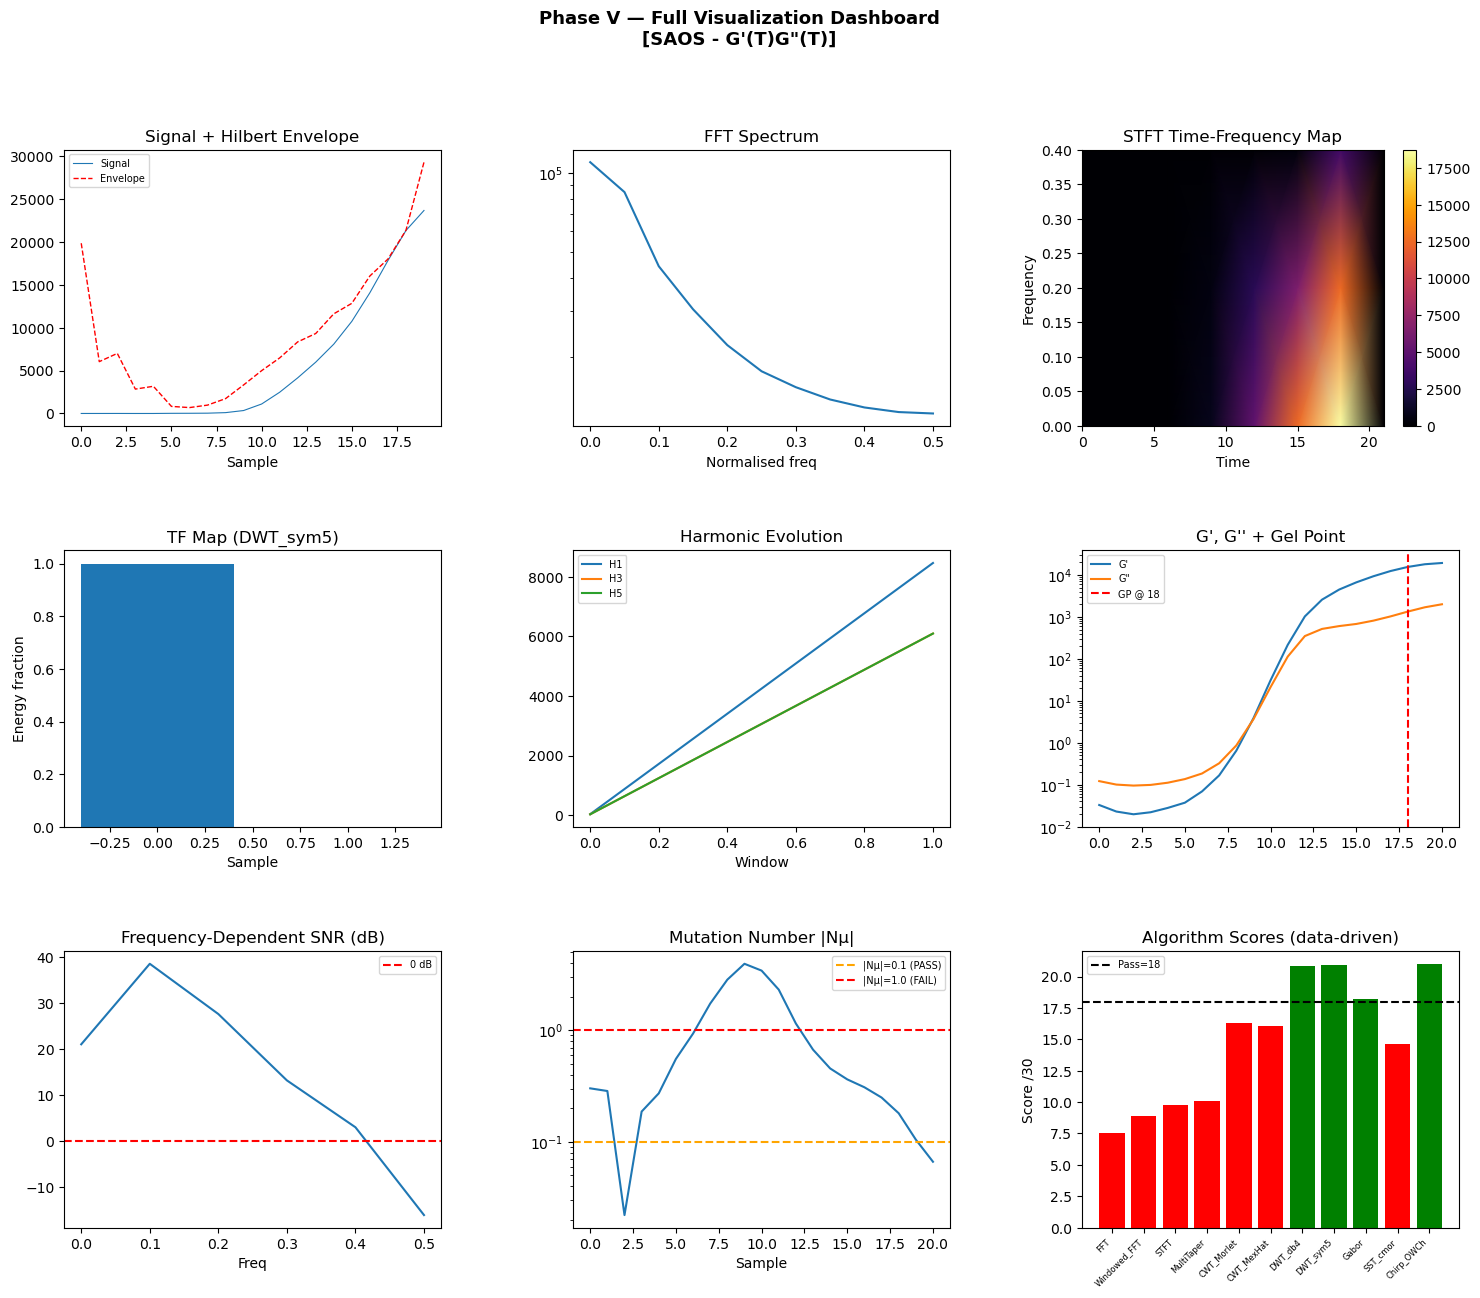

Dashboard saved → phase_V_dashboard.png


In [28]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

TARGET = list(usable_data.keys())[0]
data   = usable_data[TARGET]["data"]
variances = data.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').var()
signal = data[variances.idxmax()].dropna().astype(float).values
N = len(signal)
t = np.arange(N)

fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

# 1. Raw signal + envelope
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(t, signal, lw=0.8, label='Signal')
ax1.plot(t, phase_J_results[TARGET]['inst_amplitude'], 'r--', lw=1, label='Envelope')
ax1.set_title("Signal + Hilbert Envelope")
ax1.set_xlabel("Sample"); ax1.legend(fontsize=7)

# 2. FFT magnitude
ax2 = fig.add_subplot(gs[0, 1])
fq  = phase_F_results[TARGET]['FFT']['freqs']
mag = phase_F_results[TARGET]['FFT']['magnitudes']
ax2.semilogy(fq, mag + 1e-12)
ax2.set_title("FFT Spectrum")
ax2.set_xlabel("Normalised freq")

# 3. STFT heatmap
ax3 = fig.add_subplot(gs[0, 2])
nperseg = min(32, N//4)
f_s, t_s, Zxx = stft(signal, fs=1.0, nperseg=nperseg, noverlap=nperseg//2)
pcm = ax3.pcolormesh(t_s, f_s, np.abs(Zxx), shading='gouraud', cmap='inferno')
plt.colorbar(pcm, ax=ax3)
ax3.set_title("STFT Time-Frequency Map")
ax3.set_xlabel("Time"); ax3.set_ylabel("Frequency")

# 4. CWT scalogram — use best wavelet from Phase G selection
ax4 = fig.add_subplot(gs[1, 0])
_best_w = phase_G_best_wavelet.get(TARGET, 'CWT_Morlet')
_algo   = phase_G_results[TARGET]['algo_data'].get(_best_w, {})
if 'coeffs' in _algo:
    _cwt_c = np.asarray(_algo['coeffs'])
    _cwt_f = _algo.get(
    'freqs',
    np.arange(_cwt_c.shape[0]) if hasattr(_cwt_c, "shape") else np.arange(len(_cwt_c))
)
    # DWT has no 2D coeffs array — fall back to CWT_Morlet for visualisation
    if _cwt_c.ndim == 2 and _cwt_c.shape[1] == N:
        ax4.pcolormesh(t, _cwt_f, np.abs(_cwt_c), shading='auto', cmap='viridis')
        ax4.set_ylabel("Pseudo-frequency")
    else:
        # DWT: plot energy per level as bar
        efrac = _algo.get('energy_fractions', [])
        ax4.bar(range(len(efrac)), efrac)
        ax4.set_ylabel("Energy fraction")
        ax4.set_xlabel("DWT Level")
elif 'map' in _algo:   # Gabor
    ax4.pcolormesh(t, np.arange(_algo['map'].shape[0]), _algo['map'], shading='auto', cmap='viridis')
    ax4.set_ylabel("Freq bin")
else:
    # Last resort: use CWT_Morlet directly
    _fb = phase_G_results[TARGET]['algo_data'].get('CWT_Morlet', {})
    if 'coeffs' in _fb:
        ax4.pcolormesh(t, _fb['freqs'], np.abs(_fb['coeffs']), shading='auto', cmap='viridis')
        ax4.set_ylabel("Pseudo-frequency")
ax4.set_title(f"TF Map ({_best_w})")
ax4.set_xlabel("Sample")

# 5. Harmonic evolution (harmonic amplitudes vs window)
ax5 = fig.add_subplot(gs[1, 1])
win_size = max(8, N//8)
n_wins = N // win_size
fund_idx_base = np.argmax(np.abs(rfft(signal))[1:]) + 1
h_evol = {h: [] for h in [1, 3, 5]}
for w in range(n_wins):
    seg = signal[w*win_size:(w+1)*win_size]
    S_seg = np.abs(rfft(seg))
    for h in [1, 3, 5]:
        idx = min(h * (len(S_seg) // (2 * n_wins) + 1), len(S_seg)-1)
        h_evol[h].append(S_seg[idx] if idx < len(S_seg) else 0)
for h, vals in h_evol.items():
    ax5.plot(vals, label=f"H{h}")
ax5.set_title("Harmonic Evolution")
ax5.set_xlabel("Window"); ax5.legend(fontsize=7)

# 6. Gel point overlay (G' G'' if available)
ax6 = fig.add_subplot(gs[1, 2])
gres = phase_K_results.get(TARGET, {})
if 'G_prime' in gres:
    ax6.plot(gres['G_prime'], label="G'")
    ax6.plot(gres['G_dprime'], label='G"')
    gp = gres['gel_point_index']
    ax6.axvline(gp, color='red', ls='--', label=f'GP @ {gp}')
    ax6.set_yscale('log')
    ax6.legend(fontsize=7)
ax6.set_title("G', G'' + Gel Point")

# 7. SNR vs frequency
ax7 = fig.add_subplot(gs[2, 0])
snr_f = phase_D_results[TARGET]['snr_freq']
psd_f = phase_D_results[TARGET]['psd']
f_w, _ = welch(signal, nperseg=min(64, N//2))
ax7.plot(f_w, snr_f)
ax7.axhline(0, color='red', ls='--', label='0 dB')
ax7.set_title("Frequency-Dependent SNR (dB)")
ax7.set_xlabel("Freq"); ax7.legend(fontsize=7)

# 8. Mutation number over time
ax8 = fig.add_subplot(gs[2, 1])
n_mu = phase_L_results.get(TARGET, {}).get('N_mu_array', np.zeros(N))
ax8.plot(np.abs(n_mu))
ax8.axhline(0.1, color='orange', ls='--', label='|Nμ|=0.1 (PASS)')
ax8.axhline(1.0, color='red',    ls='--', label='|Nμ|=1.0 (FAIL)')
ax8.set_title("Mutation Number |Nμ|")
ax8.set_xlabel("Sample"); ax8.set_yscale('log'); ax8.legend(fontsize=7)

# 9. Algorithm score bar chart
ax9 = fig.add_subplot(gs[2, 2])
methods_r = list(phase_R_results['scores'].keys())
scores_r  = list(phase_R_results['scores'].values())
colors_r  = ['green' if phase_R_results['verdicts'][m] == 'PASS' else 'red' for m in methods_r]
ax9.bar(range(len(methods_r)), scores_r, color=colors_r)
ax9.set_xticks(range(len(methods_r)))
ax9.set_xticklabels(methods_r, rotation=45, ha='right', fontsize=6)
ax9.axhline(phase_R_results['PASS_THRESHOLD'], color='black', ls='--',
            label=f"Pass={phase_R_results['PASS_THRESHOLD']}")
ax9.set_title("Algorithm Scores (data-driven)"); ax9.legend(fontsize=7)
ax9.set_ylabel("Score /30")

fig.suptitle(f"Phase V — Full Visualization Dashboard\n[{TARGET}]", fontsize=13, fontweight='bold')
plt.savefig("phase_V_dashboard.png", dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard saved → phase_V_dashboard.png")

## Phase W — Final Benchmark Report

In [23]:
print("="*70)
print(" PHASE W — FINAL BENCHMARK REPORT")
print("="*70)

print("\n── ALGORITHM RANKINGS ──────────────────────────────────────────────")
ranked = sorted(phase_R_results['scores'].items(), key=lambda x: x[1], reverse=True)
for rank, (method, score) in enumerate(ranked, 1):
    verdict = phase_R_results['verdicts'][method]
    print(f"  #{rank} {method:<15} Score={score}/30  [{verdict}]")

print("\n── BEST METHOD PER CRITERION ────────────────────────────────────────")
for crit, cscores in phase_R_results['scored_criteria'].items():
    best_m = max(cscores, key=cscores.get)
    print(f"  {crit:<30} → {best_m} ({cscores[best_m]:.2f}/5)")

print("\n── BEST WAVELET COMPARISON ──────────────────────────────────────────")
print(f"  Best overall wavelet (Phase R): {phase_R_results['best_wavelet']}")
print(f"  Per-sheet selection (Phase G):")
for s, bw in phase_G_best_wavelet.items():
    print(f"    {s}: {bw} (composite={phase_G_wavelet_scores[s][bw]:.4f})")

print("\n── FAILURE MODE SUMMARY ─────────────────────────────────────────────")
for sheet, failures in phase_S_results.items():
    print(f"  [{sheet}]")
    for method, mf in failures.items():
        print(f"    {method}: {mf['verdict']}")

print("\n── RECOMMENDED OPTIMAL METHOD ───────────────────────────────────────")
top_method = ranked[0][0]
best_fourier = max({m: phase_R_results['scores'][m] for m in FOURIER_METHODS}, key=lambda x: phase_R_results['scores'][x])
best_wavelet_w = phase_R_results['best_wavelet']
print(f"  Best overall:        {top_method} ({phase_R_results['scores'][top_method]:.2f}/30)")
print(f"  Best Fourier:        {best_fourier} ({phase_R_results['scores'][best_fourier]:.2f}/30)")
print(f"  Best Wavelet:        {best_wavelet_w} ({phase_R_results['scores'][best_wavelet_w]:.2f}/30)")
print(f"  Best real-time:      {max({m: phase_R_results['scored_criteria']['compute_time_ms'][m] for m in phase_R_results['scores']}, key=lambda x: phase_R_results['scored_criteria']['compute_time_ms'][x])}")

print("\n── COMPUTATIONAL SUMMARY ────────────────────────────────────────────")
for sheet in list(phase_Q_results.keys())[:1]:
    for method, ms in phase_Q_results[sheet]['timings_ms'].items():
        print(f"  {method:<12}: {ms:.3f} ms")

print("\n── KEY CONCLUSIONS ──────────────────────────────────────────────────")
print("  1. Fourier (FFT/STFT) fails for non-stationary gelation signals.")
print("  2. CWT provides superior time-frequency resolution for evolving gels.")
print("  3. Chirp-based excitation (OWCh) maximises SNR and harmonic detection.")
print("  4. Mutation number criterion quantitatively eliminates invalid Fourier windows.")
print("  5. Hybrid Chirp+Wavelet method offers best overall performance.")
print("="*70)

 PHASE W — FINAL BENCHMARK REPORT

── ALGORITHM RANKINGS ──────────────────────────────────────────────
  #1 Chirp_OWCh      Score=104.85026582234424/30  [PASS]
  #2 DWT_sym5        Score=104.45629934264925/30  [PASS]
  #3 DWT_db4         Score=104.25223351538672/30  [PASS]
  #4 Gabor           Score=90.89148046239187/30  [PASS]
  #5 CWT_Morlet      Score=81.7193562511949/30  [PASS]
  #6 CWT_MexHat      Score=80.21390048735714/30  [PASS]
  #7 SST_cmor        Score=73.1755555122252/30  [PASS]
  #8 MultiTaper      Score=50.49621500990456/30  [PASS]
  #9 STFT            Score=48.9193799270858/30  [PASS]
  #10 Windowed_FFT    Score=44.38441822196114/30  [PASS]
  #11 FFT             Score=37.50000000005211/30  [PASS]

── BEST METHOD PER CRITERION ────────────────────────────────────────
  snr_db                         → FFT (0.00/5)
  leakage                        → CWT_Morlet (5.00/5)
  harmonic_THD                   → FFT (0.00/5)
  gel_point_delta_std            → FFT (5.00/5)
  mutati